# NB_L2 — End-to-end: LeanGate selection → DKM → bias selection → seam variants

One notebook, the whole pipeline. **Supersedes NB_L1** — Pass A lives here now, so there
is exactly one copy of it and nothing to drift between notebooks.

```
Pass A   (every sequence)   native decode -> SIFT-500 probe -> S = min(f_m, f_u)
                            -> gate omega=0.164 -> exact DAG path -> DKM with
                            re-plan on rejection -> cost fields + correspondences
Selection (MovingDrone)     compose dgeo/sem across BIAS_GRID -> SLC -> ONE global
                            bias -> frozen to disk
Pass B   (own videos)       firstwins, dgeo, sem, hybrid x5, random_seam at the
                            frozen bias -> mosaics + maps + SLC + runtimes
```

## Decisions this notebook implements

| decision | why |
|---|---|
| Frames chosen by LeanGate, not 1 Hz | report of 17 Sep 2026; southroad 54.5% -> 96.3% coverage |
| Re-plan on DKM rejection | never pairs frames the probe did not vet |
| **One global bias**, selected on held-out MovingDrone, frozen | pipeline must generalise to unseen footage; no per-video tuning |
| Per-family optimum reported as a **diagnostic only** | shows whether the single value handicaps d_geo or sem |
| **SLC** as the main metric | validated against a known-parallax scene; HVA failed the same test |
| Comparison is stitching-only | every variant shares one registration per video |

## The main metric: seam-line source consistency (SLC)

At each seam pixel, the NCC between the **two source frames** that meet there, in a 15-px
window. Low means the seam cuts where the frames disagree — a visible break.

Provenance: source disagreement along the seam is the seam-quality criterion of graph-cut
texture synthesis (Kwatra et al., SIGGRAPH 2003) and interactive photomontage (Agarwala et
al., SIGGRAPH 2004). They optimise it; this evaluates it after the fact.

**Validated against a scene with a raised block of known parallax:**

| parallax | around-block | through-block |
|---|---|---|
| none | 0.000 | 0.000 |
| 4.6 px | 0.000 | 0.287 |
| 80 px | 0.000 | 0.286 |

`slc_frac_disagree` = fraction of seam length cutting through disagreement. The
through-block seam scores 0.287; the block occupies 0.333 of that seam's length.

**And end to end through NB_S4's real composition code**, on a five-frame scene with a
raised block (k = 0.35), four seeds:

| | `dgeo` | `firstwins` | `random` |
|---|---|---|---|
| no parallax | 0.000 | 0.000 | 0.000 |
| k = 0.35 | **0.000** | 0.081 | 0.078 |

`d_geo` routes entirely around the block; `firstwins` and `random`, both blind to it, cut
through it at nearly the same rate.

**Masked NCC.** Correlation is taken only over pixels where both frames exist, requiring at
least 40% of the window. The first version demanded the full window, which made
`firstwins` unscoreable: its seam *is* the old frame's footprint edge, so a centred window
always loses that frame on one side.

**It saturates.** Beyond the 15-px window NCC is near-uncorrelated regardless of how much
further the displacement goes, so SLC *detects* disagreement rather than sizing it. The
headline is therefore the fraction below threshold, not the mean.

**What it is not independent of.** No variant here routes on photometric disagreement, so
SLC is not any router's objective. But it measures the physical quantity `d_geo` targets
— misregistration where the seam falls — through raw pixels instead of DKM's flow. `d_geo`
scoring well is therefore evidence that DKM's flow was right, not an independent verdict
on the question. `firstwins` and `random_seam` are what calibrate how much of a win is real.

## Why HVA was dropped

Held-out views sit between the source frames and see a raised block at intermediate
positions, so under parallax **no composition agrees with every viewpoint**. On the same
known-answer scene HVA scored the through-block seam *better* than around-block
(+0.032 at k = 0.25). It rewards average-consistency over structural integrity.

## 1. Configuration

In [1]:
from pathlib import Path
import json, sys, os, time, math, shutil
import numpy as np, cv2

PROJECT  = Path(r"C:\Major Project\UAV_Mosaicking_Project")
DATA     = PROJECT / "data"
ROOT     = PROJECT / "evaluation_validation" / "leangate"
PASSA    = ROOT / "passA"          # reuses the eval-video caches NB_L1 already built
PASSB    = ROOT / "passB"
for d in (PASSA, PASSB): d.mkdir(parents=True, exist_ok=True)

DKM_REPO = PROJECT / "DKM"
SEMSTITCH_REPO = PROJECT / "OAIV-Coherence"
SEMSTITCH_CKPT = PROJECT / "OAIV-Coherence" / "checkpoints" / "epoch090_model.pth"
SEMSTITCH_ARCH = "plain"

# ---- sequences --------------------------------------------------------
# Validation: lowest-tilt MovingDrone sequences (20-26 deg mean, all sweep near nadir),
# spanning relief/AGL 0.08 -> 0.43. None is an evaluation video.
VAL_SEQS    = ["rural8", "suburban3", "road5"]
EVAL_VIDEOS = ["birdseyecity", "redroofcity", "resort", "southroad"]
ALL_VIDEOS  = VAL_SEQS + EVAL_VIDEOS

def resolve_video(name):
    """Own videos live flat in own_videos/; MovingDrone ones in <seq>/video.mp4."""
    if name in VAL_SEQS:
        p = DATA / "MovingDrone" / name / "video.mp4"
        if p.exists(): return p
    for ext in (".mp4", ".MP4", ".mov", ".MOV"):
        p = DATA / "own_videos" / f"{name}{ext}"
        if p.exists(): return p
    raise FileNotFoundError(f"no video found for {name!r}")

# ---- decode + probe (report appendix) ---------------------------------
MAX_SIDE = 1920
PROBE_NFEATURES, LOWE_RATIO = 500, 0.80
PROBE_RANSAC, PROBE_THRESH, PROBE_CONF = cv2.USAC_MAGSAC, 12.0, 0.99
CANDIDATE_GAPS = [1, 2, 4, 8, 16, 32, 64]
OMEGA, IOU_TRUST = 0.164, 0.40

# ---- reference chain --------------------------------------------------
REF_NFEATURES, REF_THRESH, REF_CONF, REF_CANVAS_CAP = 4000, 3.0, 0.999, 6000

# ---- DKM + acceptance -------------------------------------------------
TAU_R, TAU_S, MIN_RATIO = 4.0, 3.0, 0.35
DKM_NUM_SAMPLES, UPSAMPLE_PREDS = 10000, False
NCC_WIN, MIN_STD = 9, 3.0
CORR_CACHE = True

# ---- composition (frozen from NB_FINAL_EVALUATION via NB_S4) ----------
FEATHER_PX, ERODE_PX, HOLE_FILL, CENTRE_BIAS = 24, 0, True, 0.0
AGE_BIAS     = 0.5     # added ON TOP of the selected bias -- the bias is relative to it
NEUTRAL_COST, COST_PCTL, COST_SCALE = 0.5, 95, 1.0
SEAM_MAX_SIDE, SEAM_ROI_MARGIN = 1024, 32
SEAM_MIN_SIDE, SEAM_RETRY_LADDER = 176, (176, 352, 704)
SEAM_MIN_OVERLAP_PX = 50
STEP_OFFSET, BLUR_K, N_BG_SAMPLES = 3, 5, 20000
MAX_CANVAS_MPX, COMPOSE_BATCH = 200, 3

# ---- sweeps -----------------------------------------------------------
BIAS_GRID = [0.0, 0.2, 0.5, 1.0]
HYBRID_W  = [0.0, 0.25, 0.5, 0.75, 1.0]
BIAS_TIE  = 0.005        # scores within this are ties -> prefer the smaller bias
FORCE_RESELECT = False   # True re-runs selection even if a frozen value exists

# ---- SLC --------------------------------------------------------------
SLC_WIN, SLC_THRESH, SLC_MAX_PTS = 15, 0.5, 400
# SLC_THRESH fixed from the synthetic separation (aligned 1.00, cut ~0.68, p10 < 0)
# BEFORE any real data was scored.

print(f"root {ROOT}\nval  {VAL_SEQS}\neval {EVAL_VIDEOS}")
for v in ALL_VIDEOS:
    try: print(f"  {v:13s} {resolve_video(v)}")
    except FileNotFoundError as e: print(f"  {v:13s} !! {e}")

root C:\Major Project\UAV_Mosaicking_Project\evaluation_validation\leangate
val  ['rural8', 'suburban3', 'road5']
eval ['birdseyecity', 'redroofcity', 'resort', 'southroad']
  rural8        C:\Major Project\UAV_Mosaicking_Project\data\MovingDrone\rural8\video.mp4
  suburban3     C:\Major Project\UAV_Mosaicking_Project\data\MovingDrone\suburban3\video.mp4
  road5         C:\Major Project\UAV_Mosaicking_Project\data\MovingDrone\road5\video.mp4
  birdseyecity  C:\Major Project\UAV_Mosaicking_Project\data\own_videos\birdseyecity.mp4
  redroofcity   C:\Major Project\UAV_Mosaicking_Project\data\own_videos\redroofcity.mp4
  resort        C:\Major Project\UAV_Mosaicking_Project\data\own_videos\resort.mp4
  southroad     C:\Major Project\UAV_Mosaicking_Project\data\own_videos\southroad.mp4


## 2. Environment, DKM memory patch

In [2]:
# === verbatim from NB_S5: chunked-KDE sampler ===
# ============================================================================
# Imports, environment report, DKM kde memory patch
# ============================================================================
import os, sys, json, time, math, gc, warnings
import numpy as np
import cv2
import torch
import pandas as pd

# --- NB_L1: NB_S5 config names the verbatim cells read, which NB_L1's own config
# cell does not define. Kept here so this cell is runnable on its own.
RANDOM_SEED     = 0                 # NB_S5 value
PREFER_GCRANSAC = True              # NB_S5 value; falls back to cv2.USAC_MAGSAC
NUM_SAMPLE      = DKM_NUM_SAMPLES   # NB_S5's name for the same value (10000)
RANSAC_CONF     = 0.99              # NB_S5 value, read inside dual_layer
RANSAC_ITERS    = 10000             # NB_S5 value, read inside dual_layer

if str(DKM_REPO):
    sys.path.insert(0, str(DKM_REPO))

np.random.seed(RANDOM_SEED)
cv2.setRNGSeed(RANDOM_SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("python  ", sys.version.split()[0])
print("opencv  ", cv2.__version__)
print("torch   ", torch.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print("gpu     ", torch.cuda.get_device_name(0),
          f"{torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# --- robust estimator availability -----------------------------------------
HAS_GCRANSAC = False
if PREFER_GCRANSAC:
    try:
        import pygcransac
        HAS_GCRANSAC = True
        print("pygcransac available")
    except ImportError as e:
        print("pygcransac NOT available ->", e, "| falling back to cv2.USAC_MAGSAC")

# --- DKM kde chunking patch -------------------------------------------------
# DKMv3 ships sample_mode='threshold_balanced', so the kde path is the DEFAULT, not opt-in.
# The stock kde materialises a full NxN cdist and OOMs on 8 GB. Same values, chunked.
def _kde_chunked(x, std=0.1, batch_size=1000):
    x = x.half()
    density = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)
    for i in range(0, x.shape[0], batch_size):
        d = torch.cdist(x[i:i+batch_size], x)
        density[i:i+batch_size] = (-d**2 / (2*std**2)).exp().sum(dim=-1)
    return density

import dkm.utils.kde as _kde_mod
_kde_mod.kde = _kde_chunked
import dkm.models.dkm as _dkm_mod
if hasattr(_dkm_mod, "kde"):
    _dkm_mod.kde = _kde_chunked          # it was imported by name, so patch the binding too
print("kde patched:", _dkm_mod.kde is _kde_chunked if hasattr(_dkm_mod, "kde") else "module-level only")

python   3.10.11
opencv   4.13.0
torch    2.11.0+cu128 | device: cuda
gpu      NVIDIA GeForce RTX 4060 Laptop GPU 8.6 GB
pygcransac available
kde patched: module-level only


## 3. Pass A — frame selection

From NB_L1, unchanged except that videos are located through `resolve_video` so MovingDrone
and own footage share one code path.

In [3]:
def decode_native(video_name, force=False):
    vp = resolve_video(video_name)          # NB_L2: one resolver, both datasets

    fdir = PASSA / video_name / "frames"; fdir.mkdir(parents=True, exist_ok=True)
    man_p = PASSA / video_name / "frames_manifest.json"
    if man_p.exists() and not force:
        man = json.loads(man_p.read_text())
        if len(list(fdir.glob("*.png"))) == man["n_frames"]:
            print(f"  {video_name}: reusing {man['n_frames']} native frames")
            return man

    cap = cv2.VideoCapture(str(vp))
    fps = cap.get(cv2.CAP_PROP_FPS)
    W0, H0 = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    s = 1.0 if max(W0, H0) <= MAX_SIDE else MAX_SIDE / max(W0, H0)
    W, H = int(round(W0 * s)), int(round(H0 * s))

    i, t0 = 0, time.time()
    while True:
        ok, fr = cap.read()
        if not ok: break
        if s != 1.0:
            fr = cv2.resize(fr, (W, H), interpolation=cv2.INTER_AREA)
        cv2.imwrite(str(fdir / f"{i:06d}.png"), fr)
        i += 1
        if i % 200 == 0: print(f"    {i} frames, {time.time()-t0:.0f}s", flush=True)
    cap.release()

    man = dict(video=str(vp), n_frames=i, fps=fps, source_resolution=[W0, H0],
               working_resolution=[W, H], resize_scale=s,
               duration_s=i / fps if fps else None)
    man_p.write_text(json.dumps(man, indent=2))
    print(f"  {video_name}: {i} frames at {W}x{H}, {time.time()-t0:.0f}s")
    return man

In [4]:
def build_descriptors(video_name, nfeatures=PROBE_NFEATURES, force=False):
    d = PASSA / video_name / f"sift_{nfeatures}.npz"
    n = MANIFESTS[video_name]["n_frames"]
    if d.exists() and not force:
        z = np.load(d, allow_pickle=True)
        print(f"  {video_name}: reusing descriptors ({nfeatures} feat)")
        return list(z["kps"]), list(z["des"]), dict(z["stats"].item())

    sift = cv2.SIFT_create(nfeatures=nfeatures)
    fdir = PASSA / video_name / "frames"
    kps, des, counts = [], [], []
    t0 = time.time()
    for i in range(n):
        g = cv2.imread(str(fdir / f"{i:06d}.png"), cv2.IMREAD_GRAYSCALE)
        k, dd = sift.detectAndCompute(g, None)
        if dd is None or not len(k):
            kps.append(np.zeros((0, 2), np.float32)); des.append(np.zeros((0, 128), np.float32))
            counts.append(0); continue
        kps.append(np.array([p.pt for p in k], np.float32))
        des.append(dd.astype(np.float32))
        counts.append(len(k))
        if (i + 1) % 200 == 0: print(f"    {i+1}/{n}, {time.time()-t0:.0f}s", flush=True)

    counts = np.array(counts)
    stats = dict(mean=float(counts.mean()), min=int(counts.min()), max=int(counts.max()),
                 frac_at_budget=float((counts >= nfeatures - 5).mean()))
    np.savez_compressed(d, kps=np.array(kps, dtype=object),
                        des=np.array(des, dtype=object), stats=stats)
    print(f"  {video_name}: {n} frames, {counts.mean():.1f} +/- {counts.std():.1f} feat, "
          f"{stats['frac_at_budget']*100:.1f}% at budget, {time.time()-t0:.0f}s")
    if stats["frac_at_budget"] < 0.95:
        print(f"    !! only {stats['frac_at_budget']*100:.0f}% of frames reach the "
              f"{nfeatures}-feature budget -- normalising f_m by {nfeatures} is NOT a "
              f"fair denominator on this video (report Table 2 caveat)")
    return kps, des, stats

In [5]:
def probe_pair(kA, dA, kB, dB, shape):
    """S = min(f_m, f_u) for one candidate pair. Returns a record, never raises."""
    H_img, W_img = shape
    out = dict(f_m=0.0, f_u=0.0, S=0.0, n_put=0, n_in=0, iou=0.0, ok=False)
    if len(dA) < 2 or len(dB) < 2:
        return out

    knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(dB, dA, k=2)
    src, dst = [], []
    for m in knn:
        if len(m) == 2 and m[0].distance < LOWE_RATIO * m[1].distance:
            src.append(kB[m[0].queryIdx]); dst.append(kA[m[0].trainIdx])
    n_put = len(src)
    out["n_put"] = n_put
    out["f_m"] = min(n_put / PROBE_NFEATURES, 1.0)
    if n_put < 4:
        out["S"] = 0.0; return out

    src = np.asarray(src, np.float32).reshape(-1, 1, 2)
    dst = np.asarray(dst, np.float32).reshape(-1, 1, 2)
    Hm, mask = cv2.findHomography(src, dst, PROBE_RANSAC, PROBE_THRESH,
                                  confidence=PROBE_CONF)
    if Hm is None or mask is None:
        out["S"] = 0.0; return out
    out["n_in"] = int(mask.sum())

    rect = np.float32([[0, 0], [W_img, 0], [W_img, H_img], [0, H_img]]).reshape(-1, 1, 2)
    warped = cv2.perspectiveTransform(rect, Hm)
    inter, _ = cv2.intersectConvexConvex(rect.reshape(-1, 2), warped.reshape(-1, 2))
    area = float(W_img * H_img)
    aw = cv2.contourArea(warped.astype(np.float32))
    union = area + aw - inter
    out["iou"] = float(inter / union) if union > 1e-9 else 0.0
    out["f_u"] = float(inter / area)

    # Below IOU_TRUST the proxy homography is unreliable, so f_u cannot be believed.
    if out["iou"] < IOU_TRUST:
        out["S"] = 0.0; out["ok"] = False; return out

    out["S"] = float(min(out["f_m"], out["f_u"]))
    out["ok"] = out["S"] >= OMEGA
    return out


def build_edges(video_name):
    kps, des, _ = DESC[video_name]
    n = MANIFESTS[video_name]["n_frames"]
    W, H = MANIFESTS[video_name]["working_resolution"]
    edges, t0, done = {}, time.time(), 0
    total = sum(max(0, n - g) for g in CANDIDATE_GAPS)
    for g in CANDIDATE_GAPS:
        for i in range(0, n - g):
            r = probe_pair(kps[i], des[i], kps[i + g], des[i + g], (H, W))
            if r["ok"]:
                edges[(i, i + g)] = r
            done += 1
            if done % 2000 == 0:
                print(f"    {done}/{total} probes, {len(edges)} edges, "
                      f"{time.time()-t0:.0f}s", flush=True)
    dt = time.time() - t0
    print(f"  {video_name}: {total} probes in {dt:.0f}s "
          f"({dt/max(total,1)*1000:.1f} ms/pair), {len(edges)} edges pass omega")
    return edges

In [6]:
def solve_path(edges, start, n, banned=frozenset()):
    """Fewest DKM calls from `start` towards n-1, over probe-vetted edges only.

    Lexicographic cost (hops, sum of squared gaps). Hops is the DKM-call count and
    dominates. Sum g^2 only breaks ties between equal-hop routes, preferring the more
    even spread of gap SIZES. It is order-invariant: it chooses the multiset of gaps,
    not where the short hops sit.

    On birdseyecity it is a no-op -- 883 = 13x64 + 32 + 16 + 2 + 1 is the only 17-hop
    decomposition, and 883 is odd while 1 is the only odd candidate gap, so a gap of
    1 is forced. It bites where equal-hop routes differ in their gap multiset, which
    re-planning after a rejection can create.

    If n-1 is unreachable, the path ends at the furthest reachable node so the caller
    can see the chain was truncated.
    """
    adj = {}
    for (i, j) in edges:
        if i >= start and (i, j) not in banned:
            adj.setdefault(i, []).append(j)
    best, prev = {start: (0, 0)}, {start: -1}
    for i in range(start, n):
        if i not in best:
            continue
        h, s = best[i]
        for j in adj.get(i, ()):
            c = (h + 1, s + (j - i) ** 2)
            if j not in best or c < best[j]:
                best[j], prev[j] = c, i
    t = n - 1
    while t > start and t not in best:
        t -= 1
    path, k = [], t
    while k != -1:
        path.append(k); k = prev[k]
    return path[::-1]


def select_greedy(edges, n):
    """Largest permitted jump at each step -- what most keyframe work does."""
    adj = {}
    for (i, j) in edges: adj.setdefault(i, []).append(j)
    path, cur = [0], 0
    while cur < n - 1:
        nxt = max(adj.get(cur, [-1]))
        if nxt <= cur: break
        path.append(nxt); cur = nxt
    return path

In [7]:
def build_reference(video_name, force=False):
    out = PASSA / video_name / "reference"; out.mkdir(parents=True, exist_ok=True)
    if (out / "chain.npz").exists() and not force:
        z = np.load(out / "chain.npz")
        print(f"  {video_name}: reusing reference chain "
              f"({z['G'].shape[0]} frames, {int(z['n_breaks'])} breaks)")
        return z["G"], int(z["n_breaks"])

    n = MANIFESTS[video_name]["n_frames"]
    fdir = PASSA / video_name / "frames"
    sift = cv2.SIFT_create(nfeatures=REF_NFEATURES)
    bf = cv2.BFMatcher(cv2.NORM_L2)

    G = np.zeros((n, 3, 3), np.float64); G[0] = np.eye(3)
    breaks, t0 = [], time.time()
    prev = None
    for i in range(n):
        g = cv2.imread(str(fdir / f"{i:06d}.png"), cv2.IMREAD_GRAYSCALE)
        k, d = sift.detectAndCompute(g, None)
        cur = (np.array([p.pt for p in k], np.float32) if k else np.zeros((0, 2), np.float32),
               d if d is not None else np.zeros((0, 128), np.float32))
        if prev is not None:
            H = None
            if len(cur[1]) >= 2 and len(prev[1]) >= 2:
                knn = bf.knnMatch(cur[1], prev[1], k=2)
                src, dst = [], []
                for m in knn:
                    if len(m) == 2 and m[0].distance < LOWE_RATIO * m[1].distance:
                        src.append(cur[0][m[0].queryIdx]); dst.append(prev[0][m[0].trainIdx])
                if len(src) >= 8:
                    H, _ = cv2.findHomography(
                        np.asarray(src, np.float32).reshape(-1, 1, 2),
                        np.asarray(dst, np.float32).reshape(-1, 1, 2),
                        cv2.USAC_MAGSAC, REF_THRESH, confidence=REF_CONF)
            if H is None:
                breaks.append(i); H = np.eye(3)
            G[i] = G[i - 1] @ H
        prev = cur
        if (i + 1) % 200 == 0:
            print(f"    {i+1}/{n}, {len(breaks)} breaks, {time.time()-t0:.0f}s", flush=True)

    np.savez_compressed(out / "chain.npz", G=G, n_breaks=len(breaks),
                        breaks=np.array(breaks, np.int32))
    print(f"  {video_name}: reference chain over {n} frames, {len(breaks)} breaks, "
          f"{time.time()-t0:.0f}s")
    if breaks:
        print(f"    !! {len(breaks)} chain break(s) -- A_observed is NOT continuous; "
              f"the coverage denominator is unsound for this video")
    return G, len(breaks)

In [8]:
def observed_area(video_name, cap=REF_CANVAS_CAP):
    G, _ = REFERENCE[video_name]
    W, H = MANIFESTS[video_name]["working_resolution"]
    rect = np.float32([[0, 0], [W, 0], [W, H], [0, H]]).reshape(-1, 1, 2)
    quads = [cv2.perspectiveTransform(rect, g).reshape(-1, 2) for g in G]
    P = np.concatenate(quads, 0)
    x0, y0 = np.floor(P.min(0)); x1, y1 = np.ceil(P.max(0))
    w, h = x1 - x0, y1 - y0
    s = min(1.0, cap / max(w, h))
    CW, CH = int(w * s), int(h * s)
    T = np.diag([s, s, 1.0]) @ np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]], float)

    mask = np.zeros((CH, CW), np.uint8)
    for q in quads:
        qq = cv2.perspectiveTransform(q.reshape(-1, 1, 2).astype(np.float32),
                                      np.eye(3)).reshape(-1, 2)
        pt = (T[:2, :2] @ qq.T + T[:2, 2:3]).T
        cv2.fillConvexPoly(mask, np.round(pt).astype(np.int32), 1)
    np.savez_compressed(PASSA / video_name / "reference" / "observed.npz",
                        mask=mask.astype(bool), T=T, scale=s, canvas=(CW, CH))
    print(f"  {video_name}: A_observed {CW}x{CH} at scale {s:.3f}, "
          f"{int(mask.sum())} px")
    return mask.astype(bool), T, s

## 4. DKM, dual-layer constraint, residual fields

In [9]:
# === verbatim from NB_S5: DKM matcher ===
# ============================================================================
# DKM wrapper -- returns sampled correspondences AND the dense field
# ============================================================================
from dkm import DKMv3_outdoor

_MODEL = None
def get_model():
    global _MODEL
    if _MODEL is None:
        t0 = time.time()
        _MODEL = DKMv3_outdoor(device=DEVICE)
        # === NB_L1: the NB_S5 original never set this, so it inherited DKM's
        # default and UPSAMPLE_PREDS in the config was applied to nothing. The
        # earlier Pass A traces recorded False from the config constant while the
        # model ran on its default -- a provenance error. Set it, then read it back.
        _MODEL.upsample_preds = UPSAMPLE_PREDS
        actual = getattr(_MODEL, "upsample_preds", "attribute missing")
        if actual != UPSAMPLE_PREDS:
            raise RuntimeError(f"upsample_preds is {actual!r} after setting "
                               f"{UPSAMPLE_PREDS!r} -- this DKM build ignores it")
        print(f"DKM loaded in {time.time()-t0:.1f}s | upsample_preds={actual}")
    return _MODEL


def dkm_match(img_ref_path, img_new_path):
    # ref = A (the frame already on the canvas), new = B (the frame being added).
    # Returns kA/kB in pixels, plus the dense A-side field needed for d_geo.
    model = get_model()
    A = cv2.imread(str(img_ref_path)); B = cv2.imread(str(img_new_path))
    HA, WA = A.shape[:2]; HB, WB = B.shape[:2]

    warp, cert = model.match(str(img_ref_path), str(img_new_path), device=DEVICE)

    # sample() expects the full (possibly symmetric) field, exactly as in DKM's own demo
    matches, mconf = model.sample(warp, cert, num=NUM_SAMPLE)
    kA, kB = model.to_pixel_coordinates(matches, HA, WA, HB, WB)
    kA = kA.detach().cpu().numpy().astype(np.float64)
    kB = kB.detach().cpu().numpy().astype(np.float64)

    # keep only the A->B half of the symmetric field
    if getattr(model, "symmetric", False):
        half = warp.shape[1] // 2
        warp_A, cert_A = warp[:, :half], cert[:, :half]
    else:
        warp_A, cert_A = warp, cert

    warp_A = warp_A.detach().cpu().numpy()      # (h, w, 4), normalised coords
    cert_A = cert_A.detach().cpu().numpy()      # (h, w)
    return kA, kB, warp_A, cert_A, A, B

In [10]:
# === verbatim from NB_S5: dual-layer constraint + homography fit ===
# ============================================================================
# Geometry -- Zhou dual-layer constraint, unchanged
# ============================================================================
# Layer 1: Sampson / epipolar (tau_s).  Layer 2: homography reprojection (tau_r).
# Note the known theoretical caveat: on planar nadir scenes F is degenerate, so layer 1 is
# close to inert. It is kept because removing it would be a pipeline redesign, not a fix.

# pygcransac's real binding is:
#   findHomography(correspondences: (N,4) float64, h1, w1, h2, w2,
#                  probabilities: (N,) float64, threshold=1.0, conf=0.99,
#                  spatial_coherence_weight=0.975, max_iters=10000, ..., sampler=1, ...)
# Note: ONE Nx4 array (not two Nx2), `probabilities` is REQUIRED and positional, and the
# image dims are h,w order -- not w,h. Getting any of these wrong raises TypeError, which
# is exactly what the old notebook swallowed with a bare except while reporting "gcransac".
#
# sampler=0 (uniform) is used deliberately. The default sampler=1 is PROSAC, which assumes
# the correspondences are sorted by descending quality; DKM's sample() does not return them
# sorted, so PROSAC on this input would be sampling on a meaningless ordering. Uniform
# sampling is canonical GC-RANSAC (Barath & Matas 2018) and matches what Zhou's paper implies.

_GC_DISABLED = False


def _residual_mask(H, src, dst, thr):
    # Recompute the inlier mask from H by reprojection residual, ignoring whatever mask the
    # estimator returned.
    #
    # WHY: the resort run came back with n_inliers of exactly 9988/9988, 9990/9990, 10000/10000
    # or exactly 0 on every single step -- a mask carrying no information. The homographies
    # themselves were fine (the accumulated G chain was smooth and monotone), so GC-RANSAC was
    # estimating correctly and only its mask was unreadable here. Six steps were bridged for no
    # reason. Recomputing the residual ourselves makes inlier_ratio mean the same thing for
    # every estimator, so the acceptance gate compares like with like.
    src_h = np.hstack([np.asarray(src, np.float64), np.ones((len(src), 1))])
    proj = (H @ src_h.T).T
    z = proj[:, 2:3]
    z = np.where(np.abs(z) < 1e-9, 1e-9, z)
    resid = np.linalg.norm(proj[:, :2] / z - np.asarray(dst, np.float64), axis=1)
    return resid < thr, resid


def _fit_homography(src, dst, thr):
    # src -> dst.  Returns (H, inlier_mask, estimator_name).
    global _GC_DISABLED
    if HAS_GCRANSAC and not _GC_DISABLED:
        try:
            corr = np.ascontiguousarray(
                np.hstack([np.asarray(src, np.float64), np.asarray(dst, np.float64)]), np.float64)
            probs = np.ascontiguousarray(np.ones(len(corr), np.float64))
            H, mask = pygcransac.findHomography(
                corr,
                int(GC_H1), int(GC_W1), int(GC_H2), int(GC_W2),   # h,w order -- src then dst
                probs,
                threshold=float(thr), conf=float(RANSAC_CONF),
                spatial_coherence_weight=0.975, max_iters=int(RANSAC_ITERS),
                sampler=0,
            )
            H = np.asarray(H, np.float64) if H is not None else None
            if H is not None and H.size == 9:
                H = H.reshape(3, 3)
                m, _ = _residual_mask(H, src, dst, thr)     # NOT the estimator's own mask
                return H, m, "gcransac"
            return None, None, "gcransac_failed"
        except TypeError as e:
            # do not crash the run, and do not retry on every subsequent step
            _GC_DISABLED = True
            print("  !! pygcransac call rejected -- falling back to MAGSAC for the whole run.")
            print("     error:", e)
            print("     binding doc:", getattr(pygcransac.findHomography, "__doc__", "(none)"))

    H, mask = cv2.findHomography(src, dst, cv2.USAC_MAGSAC, thr,
                                 confidence=RANSAC_CONF, maxIters=RANSAC_ITERS)
    if H is None:
        return None, None, "magsac_failed"
    m, _ = _residual_mask(H, src, dst, thr)
    return H, m, "magsac"


def dual_layer(kA, kB, shapeA, shapeB):
    # kA in ref, kB in new.  H maps new -> ref.
    global GC_H1, GC_W1, GC_H2, GC_W2
    GC_H1, GC_W1 = shapeB[:2]      # src = new frame
    GC_H2, GC_W2 = shapeA[:2]      # dst = ref frame

    out = dict(n_matches=len(kA))

    # --- layer 1: epipolar / Sampson -----------------------------------------
    F, fmask = cv2.findFundamentalMat(kB, kA, cv2.USAC_MAGSAC, TAU_S, RANSAC_CONF, RANSAC_ITERS)
    if F is None or fmask is None:
        keep = np.ones(len(kA), bool)
        out["n_epipolar"] = int(keep.sum()); out["epipolar_ok"] = False
    else:
        keep = fmask.astype(bool).ravel()
        out["n_epipolar"] = int(keep.sum()); out["epipolar_ok"] = True
    if keep.sum() < 8:
        keep = np.ones(len(kA), bool)

    # --- layer 2: homography --------------------------------------------------
    H, hmask, est = _fit_homography(kB[keep], kA[keep], TAU_R)
    out["estimator"] = est
    if H is None:
        out.update(n_inliers=0, inlier_ratio=0.0)
        return None, out
    n_in = int(hmask.sum())
    out["n_inliers"] = n_in
    out["inlier_ratio"] = n_in / max(1, keep.sum())
    # median residual: a ratio pinned to exactly 0.0 or 1.0 on every step is a broken mask,
    # and this number tells you which it is without rerunning anything.
    _, resid = _residual_mask(H, kB[keep], kA[keep], TAU_R)
    out["resid_median"] = float(np.median(resid))
    out["resid_p95"] = float(np.percentile(resid, 95))
    return H, out


def area_ratio(H, shapeB):
    h, w = shapeB[:2]
    c = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
    warped = cv2.perspectiveTransform(c, H).reshape(-1,2)
    a0 = w*h
    a1 = 0.5*abs(np.dot(warped[:,0], np.roll(warped[:,1],-1)) -
                 np.dot(warped[:,1], np.roll(warped[:,0],-1)))
    return float(a1/a0) if a0 > 0 else 0.0

In [11]:
# === verbatim from NB_S5: d_geo, d_phot, certainty, cost normalisation ===
# ============================================================================
# Cost fields:  d_geo (free, from DKM), d_phot (NCC), certainty
# ============================================================================

def dense_geo_residual(warp_A, H, shapeA, shapeB):
    # d_geo(p) = || p - H . q_dkm(p) ||, in ref-frame pixels.
    #
    # warp_A[...,0:2] = normalised coords in the REF grid, warp_A[...,2:4] = the matching
    # normalised coords in the NEW frame. H maps new -> ref. So for every ref pixel we have
    # what DKM says it corresponds to, and what the fitted planar model says it should be.
    # Where the scene obeys the homography these agree; where it is raised, they cannot.
    # This is exactly the field that gets thrown away after findHomography.
    HA, WA = shapeA[:2]; HB, WB = shapeB[:2]
    h, w = warp_A.shape[:2]

    px = (warp_A[..., 0] + 1) * WA / 2.0
    py = (warp_A[..., 1] + 1) * HA / 2.0
    qx = (warp_A[..., 2] + 1) * WB / 2.0
    qy = (warp_A[..., 3] + 1) * HB / 2.0

    q = np.stack([qx, qy, np.ones_like(qx)], -1).reshape(-1, 3)
    p_hat = (H @ q.T).T
    z = p_hat[:, 2:3]
    z[np.abs(z) < 1e-9] = 1e-9
    p_hat = (p_hat[:, :2] / z).reshape(h, w, 2)

    d = np.linalg.norm(np.stack([px, py], -1) - p_hat, axis=-1).astype(np.float32)
    if (h, w) != (HA, WA):
        d = cv2.resize(d, (WA, HA), interpolation=cv2.INTER_LINEAR)
    return d


def dense_certainty(cert_A, shapeA):
    HA, WA = shapeA[:2]
    c = cert_A.astype(np.float32)
    if c.shape[:2] != (HA, WA):
        c = cv2.resize(c, (WA, HA), interpolation=cv2.INTER_LINEAR)
    return c


def photometric_residual(A, B, H, win=NCC_WIN, min_std=MIN_STD):
    # d_phot = 1 - local NCC after warping new -> ref. NCC because it is invariant to
    # brightness/contrast, so exposure drift does not register as disagreement.
    # Texture gate: NCC is undefined without local contrast, so flat/shadowed pixels are
    # returned as UNKNOWN rather than as noise that reads like structure.
    HA, WA = A.shape[:2]
    a = cv2.cvtColor(A, cv2.COLOR_BGR2GRAY).astype(np.float32)
    Bw = cv2.warpPerspective(B, H, (WA, HA), flags=cv2.INTER_LINEAR)
    b = cv2.cvtColor(Bw, cv2.COLOR_BGR2GRAY).astype(np.float32)
    valid = (cv2.warpPerspective(np.ones(B.shape[:2], np.float32), H, (WA, HA)) > 0.99)

    k = (win, win)
    ma = cv2.boxFilter(a, -1, k); mb = cv2.boxFilter(b, -1, k)
    va = np.maximum(cv2.boxFilter(a*a, -1, k) - ma*ma, 0)
    vb = np.maximum(cv2.boxFilter(b*b, -1, k) - mb*mb, 0)
    cab = cv2.boxFilter(a*b, -1, k) - ma*mb
    sa, sb = np.sqrt(va), np.sqrt(vb)
    ncc = cab / (sa*sb + 1e-6)
    d = np.clip(1.0 - np.clip(ncc, -1, 1), 0, 2) / 2.0

    unknown = (~valid) | (sa < min_std) | (sb < min_std)
    d[unknown] = np.nan
    return d.astype(np.float32), unknown


def normalise_cost(d, pctl=COST_PCTL, neutral=NEUTRAL_COST):
    # Per-field normalisation by a high percentile of the KNOWN pixels, then clipped.
    # Unknown -> neutral, never 0.
    out = np.array(d, np.float32, copy=True)
    known = np.isfinite(out)
    if known.sum() < 100:
        return np.full_like(out, neutral)
    s = np.percentile(out[known], pctl)
    if not np.isfinite(s) or s <= 1e-6:
        s = 1.0
    out = np.clip(out / s, 0, 1)
    out[~known] = neutral
    return out

In [12]:
def run_geometry_replan(video_name):
    """DKM over the selection graph, re-solving the path on every rejection.

    On rejection the edge (ref, src) is banned and the path re-solved FROM THE SAME
    REFERENCE, so the next attempt is always another probe-vetted edge out of `ref`.
    The frozen-reference policy this replaces paired frame 578 with 706 on southroad
    -- gap 128, outside the candidate set, never probed -- and then cascaded through
    seven rejections. Tested against the real birdseyecity graph: no rejections
    reproduces the Pass A path exactly; one rejection re-routes with zero unvetted
    attempts; a dead end tries every vetted edge once, then stops honestly.

    Terminates: each rejection bans one edge (finite), each acceptance strictly
    advances the reference.
    """
    n = MANIFESTS[video_name]["n_frames"]
    edges = EDGES[video_name]
    fdir = PASSA / video_name / "frames"
    out  = PASSA / video_name
    (out / "steps").mkdir(parents=True, exist_ok=True)
    fp = lambda i: fdir / f"{i:06d}.png"

    banned, cur, G = set(), 0, np.eye(3)
    composited, Gs, shapes, attempts = [0], {"0": np.eye(3).tolist()}, {}, []
    shapes["0"] = list(cv2.imread(str(fp(0))).shape)
    t0 = time.time()

    while cur != n - 1:
        path = solve_path(edges, cur, n, frozenset(banned))
        if len(path) < 2:
            print(f"  [END] no vetted edge left out of frame {cur} -- chain stops "
                  f"at {cur}/{n-1}")
            break
        nxt = path[1]
        a_id = len(attempts) + 1
        t1 = time.time()

        kA, kB, warp_A, cert_A, A, B = dkm_match(fp(cur), fp(nxt))
        H, stats = dual_layer(kA, kB, A.shape, B.shape)

        # Correspondence cache for EVERY attempt, written here because NB_S5's
        # dual_layer never stashes them. src = new frame (kB), dst = reference (kA),
        # H maps src into dst -- the production-cache convention. Full DKM samples,
        # not the post-epipolar subset; NB_E8 refits with recompute_mask=True.
        src = np.asarray(kB, np.float32); dst = np.asarray(kA, np.float32)
        if H is not None and len(src):
            proj = cv2.perspectiveTransform(src.reshape(-1, 1, 2), H).reshape(-1, 2)
            inlier = np.linalg.norm(proj - dst, axis=1) < TAU_R
        else:
            inlier = np.zeros(len(src), bool)
        np.savez_compressed(out / "steps" / f"corr_{a_id:05d}.npz",
                            ref_frame=cur, src_frame=nxt, src=src, dst=dst,
                            inlier=inlier,
                            H=(np.asarray(H) if H is not None else np.full((3, 3), np.nan)))

        ok = H is not None and stats.get("inlier_ratio", 0.0) >= MIN_RATIO
        rec = dict(attempt=a_id, ref_frame=int(cur), src_frame=int(nxt),
                   gap=int(nxt - cur), accepted=bool(ok), planned_len=len(path),
                   t_step=time.time() - t1,
                   **{k: float(v) for k, v in stats.items()
                      if not k.startswith("_") and isinstance(v, (int, float, np.floating))})

        if ok:
            G = G @ H
            Gs[str(nxt)] = G.tolist()
            shapes[str(nxt)] = list(B.shape)
            d_geo = dense_geo_residual(warp_A, H, A.shape, B.shape)
            d_phot, unknown = photometric_residual(A, B, H)
            cert = dense_certainty(cert_A, A.shape)
            np.savez_compressed(out / "steps" / f"step_{nxt:06d}.npz",
                                ref_frame=cur, src_frame=nxt,
                                d_geo=d_geo.astype(np.float16),
                                d_phot=d_phot.astype(np.float16),
                                cert=cert.astype(np.float16),
                                unknown=unknown.astype(bool))
            rec["d_geo_p95"]  = float(np.nanpercentile(d_geo, 95))
            rec["d_phot_p95"] = float(np.nanpercentile(d_phot, 95))
            composited.append(nxt); cur = nxt
        else:
            banned.add((cur, nxt))
        attempts.append(rec)
        print(f"  [{'OK ' if ok else 'REJ'}] #{a_id:3d}  {rec['ref_frame']:5d} -> "
              f"{nxt:5d} (gap {nxt-rec['ref_frame']:3d})  "
              f"inlier {stats.get('inlier_ratio', 0):.3f}  "
              f"{'' if ok else f're-plan: {len(path)-1} hops left  '}"
              f"{time.time()-t1:.1f}s", flush=True)

    unvetted = [a for a in attempts if (a["ref_frame"], a["src_frame"]) not in edges]
    if unvetted:
        raise RuntimeError(f"{video_name}: {len(unvetted)} attempt(s) on pairs the "
                           f"probe never vetted -- the re-plan invariant is broken")

    trace = dict(
        video=video_name, composited_frames=[int(x) for x in composited],
        n_composited=len(composited), reached_last=bool(cur == n - 1),
        planned_frames=SELECTION[video_name]["planned"],
        Gs=Gs, shapes=shapes, attempts=attempts,
        n_attempts=len(attempts), n_rejected=sum(not a["accepted"] for a in attempts),
        config=dict(tau_r=TAU_R, tau_s=TAU_S, min_ratio=MIN_RATIO,
                    # read back from the model, NOT the config constant
                    upsample_preds=bool(getattr(get_model(), "upsample_preds", None)),
                    dkm_num_samples=DKM_NUM_SAMPLES, omega=OMEGA,
                    gaps=CANDIDATE_GAPS, iou_trust=IOU_TRUST,
                    selection="exact_dag, hops then sum g^2",
                    on_reject="ban edge, re-solve from same reference",
                    corr_source="full DKM samples, every attempt"),
        wall_s=time.time() - t0)
    (out / "trace.json").write_text(json.dumps(trace, indent=2))
    print(f"  {video_name}: {len(composited)} composited, {len(attempts)} DKM calls "
          f"({trace['n_rejected']} rejected), reached end={trace['reached_last']}, "
          f"{time.time()-t0:.0f}s\n")
    return trace

## 5. Run Pass A on every sequence

Every stage caches. The four evaluation videos already have re-plan traces from NB_L1 and
are reused; the MovingDrone sequences are computed fresh. Stage times are recorded, and a
stage served from cache is marked as such rather than reported as ~0 s.

In [13]:
MANIFESTS, DESC, EDGES, SELECTION, REFERENCE, TRACES = {}, {}, {}, {}, {}, {}
PASSA_TIMES = {}

def timed(label, video, fn, cached_check):
    was_cached = cached_check()
    t0 = time.time(); out = fn()
    PASSA_TIMES.setdefault(video, {})[label] = ("cached" if was_cached
                                                 else round(time.time() - t0, 1))
    return out

for v in ALL_VIDEOS:
    print(f"\n==================== {v} ====================")
    d = PASSA / v
    MANIFESTS[v] = timed("decode", v, lambda: decode_native(v),
                         lambda: (d / "frames_manifest.json").exists())
    DESC[v] = timed("sift", v, lambda: build_descriptors(v),
                    lambda: (d / f"sift_{PROBE_NFEATURES}.npz").exists())

    n = MANIFESTS[v]["n_frames"]
    e_p = d / "edges.npz"
    if e_p.exists():
        edges = np.load(e_p, allow_pickle=True)["edges"].item()
        PASSA_TIMES[v]["probe"] = "cached"
    else:
        t0 = time.time(); edges = build_edges(v)
        np.savez_compressed(e_p, edges=np.array(edges, dtype=object))
        PASSA_TIMES[v]["probe"] = round(time.time() - t0, 1)
    EDGES[v] = set(edges.keys())
    total = sum(max(0, n - g) for g in CANDIDATE_GAPS)
    SELECTION[v] = dict(planned=solve_path(EDGES[v], 0, n),
                        greedy=select_greedy(EDGES[v], n), n_native=n,
                        n_edges=len(edges), n_candidates=total,
                        gate_binding=bool(len(edges) < total))

    REFERENCE[v] = timed("reference", v, lambda: build_reference(v),
                         lambda: (d / "reference" / "chain.npz").exists())
    if not (d / "reference" / "observed.npz").exists():
        observed_area(v)

    tp = d / "trace.json"
    if tp.exists():
        t = json.loads(tp.read_text())
        if t.get("config", {}).get("on_reject") != "ban edge, re-solve from same reference":
            raise SystemExit(f"{tp} is a frozen-reference trace -- delete it and rerun")
        TRACES[v] = t; PASSA_TIMES[v]["dkm"] = f"cached ({t['wall_s']:.0f}s when built)"
    else:
        TRACES[v] = run_geometry_replan(v)
        PASSA_TIMES[v]["dkm"] = round(TRACES[v]["wall_s"], 1)


==================== rural8 ====================
    200 frames, 16s
    400 frames, 32s
    600 frames, 47s
    800 frames, 63s
    1000 frames, 77s
    1200 frames, 92s
    1400 frames, 107s
    1600 frames, 123s
    1800 frames, 138s
  rural8: 1850 frames at 1920x1080, 142s
    200/1850, 49s
    400/1850, 98s
    600/1850, 147s
    800/1850, 201s
    1000/1850, 254s
    1200/1850, 301s
    1400/1850, 350s
    1600/1850, 399s
    1800/1850, 449s
  rural8: 1850 frames, 500.3 +/- 0.5 feat, 100.0% at budget, 524s
    2000/12823 probes, 2000 edges, 2s
    4000/12823 probes, 4000 edges, 5s
    6000/12823 probes, 6000 edges, 7s
    8000/12823 probes, 8000 edges, 9s
    10000/12823 probes, 10000 edges, 11s
    12000/12823 probes, 11998 edges, 14s
  rural8: 12823 probes in 15s (1.1 ms/pair), 12805 edges pass omega
    200/1850, 0 breaks, 55s
    400/1850, 0 breaks, 111s
    600/1850, 0 breaks, 167s
    800/1850, 0 breaks, 221s
    1000/1850, 0 breaks, 275s
    1200/1850, 0 breaks, 329s
    

C:\Major Project\UAV_Mosaicking_Project\.venv\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Major Project\UAV_Mosaicking_Project\.venv\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DKM loaded in 1.2s | upsample_preds=False


C:\Major Project\UAV_Mosaicking_Project\.venv\lib\site-packages\torch\functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4383.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


  [OK ] #  1      0 ->     1 (gap   1)  inlier 1.000  7.1s
  [OK ] #  2      1 ->     9 (gap   8)  inlier 1.000  3.0s
  [OK ] #  3      9 ->    25 (gap  16)  inlier 1.000  2.9s
  [OK ] #  4     25 ->    89 (gap  64)  inlier 0.772  4.4s
  [OK ] #  5     89 ->   153 (gap  64)  inlier 0.788  4.5s
  [OK ] #  6    153 ->   217 (gap  64)  inlier 0.829  3.3s
  [OK ] #  7    217 ->   281 (gap  64)  inlier 0.849  4.0s
  [OK ] #  8    281 ->   345 (gap  64)  inlier 0.894  2.9s
  [OK ] #  9    345 ->   409 (gap  64)  inlier 0.977  2.7s
  [OK ] # 10    409 ->   473 (gap  64)  inlier 1.000  2.7s
  [OK ] # 11    473 ->   537 (gap  64)  inlier 1.000  4.4s
  [OK ] # 12    537 ->   601 (gap  64)  inlier 1.000  2.9s
  [OK ] # 13    601 ->   665 (gap  64)  inlier 0.848  2.9s
  [OK ] # 14    665 ->   729 (gap  64)  inlier 0.684  3.4s
  [OK ] # 15    729 ->   793 (gap  64)  inlier 0.570  2.8s
  [OK ] # 16    793 ->   857 (gap  64)  inlier 0.485  2.6s
  [OK ] # 17    857 ->   921 (gap  64)  inlier 0.449  2.

In [14]:
import pandas as pd
rows = []
for v in ALL_VIDEOS:
    s, t = SELECTION[v], TRACES[v]
    rows.append(dict(set=("val" if v in VAL_SEQS else "eval"), video=v,
                     native=s["n_native"], gate_binds=s["gate_binding"],
                     planned=len(s["planned"]), composited=t["n_composited"],
                     dkm_calls=t["n_attempts"], rejected=t["n_rejected"],
                     reached_end=t["reached_last"],
                     upsample_preds=t["config"]["upsample_preds"],
                     ref_breaks=REFERENCE[v][1], **{f"t_{k}": x for k, x in PASSA_TIMES[v].items()}))
PASSA_DF = pd.DataFrame(rows)
PASSA_DF.to_csv(ROOT / "passA_all.csv", index=False)
print(PASSA_DF.to_string(index=False))
bad = PASSA_DF[~PASSA_DF.reached_end | (PASSA_DF.ref_breaks > 0)]
if len(bad):
    print("\n!! chain did not reach the end, or the reference chain broke:")
    print(bad[["video", "reached_end", "ref_breaks"]].to_string(index=False))

 set        video  native  gate_binds  planned  composited  dkm_calls  rejected  reached_end  upsample_preds  ref_breaks t_decode t_sift t_probe t_reference                    t_dkm
 val       rural8    1850        True       33          33         32         0         True           False           0    142.4  524.3    14.7       511.9                    107.1
 val    suburban3    1125        True       20          22         23         2         True           False           0     87.7  311.1     9.2       315.4                     64.8
 val        road5     362        True       14          38         71        34         True           False           0     24.1   95.2     2.9       100.5                    203.8
eval birdseyecity     884       False       18          18         17         0         True           False           0   cached cached  cached      cached  cached (50s when built)
eval  redroofcity     640       False       16          16         15         0         Tr

## 6. Composition machinery — verbatim from NB_S4

Router, bias handling, semantic seam, hybrid cost, `Canvas` and `compose_variants` exactly
as in NB_S4. **Two marked edits**, both additive:

- `vname` gains a `random` case (it would otherwise fall into the hybrid branch and fail
  on `w_sem=None`).
- `compose_variants` gains a `random` kind: a seam routed on a smooth random field, seeded
  per step. The degenerate control — a metric that cannot rank this below a real router is
  measuring nothing.

In [15]:
# ============================================================================
# Imports
# ============================================================================
import os, sys, json, time, math, gc, itertools, traceback
import numpy as np
import cv2
import torch
import pandas as pd
import matplotlib; import matplotlib.pyplot as plt

np.random.seed(RANDOM_SEED); cv2.setRNGSeed(RANDOM_SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device", DEVICE, "| cv2", cv2.__version__)

RUN_LOG = []
def log(msg=""):
    print(msg); RUN_LOG.append(str(msg))

torch 2.11.0+cu128 | device cuda | cv2 4.13.0


In [16]:
# ============================================================================
# Warping, cost normalisation, canvas bounds  [verbatim from NB_FINAL_EVALUATION]
# ============================================================================
def canvas_bounds(Gs, shapes, frame_ids):
    pts = []
    for i in frame_ids:
        h, w = shapes[i][:2]
        c = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
        pts.append(cv2.perspectiveTransform(c, Gs[i]).reshape(-1,2))
    P = np.concatenate(pts, 0)
    x0, y0 = np.floor(P.min(0)).astype(int)
    x1, y1 = np.ceil(P.max(0)).astype(int)
    T = np.array([[1,0,-x0],[0,1,-y0],[0,0,1]], np.float64)
    return (int(x1-x0), int(y1-y0)), T


def warp_frame(img, Gc, size):
    W, Hh = size
    w = cv2.warpPerspective(img, Gc, (W, Hh), flags=cv2.INTER_LINEAR)
    m = cv2.warpPerspective(np.ones(img.shape[:2], np.uint8)*255, Gc, (W, Hh),
                            flags=cv2.INTER_NEAREST)
    m = (m > 127)
    if ERODE_PX > 0:
        m = cv2.erode(m.astype(np.uint8), np.ones((ERODE_PX, ERODE_PX), np.uint8)).astype(bool)
    if HOLE_FILL:
        m = cv2.morphologyEx(m.astype(np.uint8), cv2.MORPH_CLOSE,
                             np.ones((3,3), np.uint8)).astype(bool)
    return w, m


def warp_field(field, Gc, size, fill):
    W, Hh = size
    f = np.array(field, np.float32)
    f[~np.isfinite(f)] = fill
    return cv2.warpPerspective(f, Gc, (W, Hh), flags=cv2.INTER_LINEAR,
                               borderValue=float(fill))


def normalise_cost(d, pctl=COST_PCTL, neutral=NEUTRAL_COST):
    out = np.array(d, np.float32, copy=True)
    known = np.isfinite(out)
    if known.sum() < 100:
        return np.full_like(out, neutral)
    s = np.percentile(out[known], pctl)
    if not np.isfinite(s) or s <= 1e-6:
        s = 1.0
    out = np.clip(out / s, 0, 1)
    out[~known] = neutral
    return out


def warp_severity(G):
    A = np.asarray(G, np.float64)[:2, :2]
    sv = np.maximum(np.linalg.svd(A, compute_uv=False), 1e-9)
    return float((max(sv[0]/sv[1], sv[1]/sv[0]) - 1.0) + abs(np.sqrt(sv[0]*sv[1]) - 1.0))


def _blank(p):
    return str(p).strip() in ("", ".")

In [17]:
# ============================================================================
# Seam routing -- DP min-error boundary cut  [verbatim from NB_FINAL_EVALUATION]
# ============================================================================
def _dp_path(cost):
    Hh, Ww = cost.shape
    M = cost.astype(np.float64).copy()
    back = np.zeros((Hh, Ww), np.int32)
    for r in range(1, Hh):
        left  = np.roll(M[r-1],  1); left[0]   = np.inf
        right = np.roll(M[r-1], -1); right[-1] = np.inf
        stack = np.stack([left, M[r-1], right])
        arg = np.argmin(stack, 0)
        M[r] += stack[arg, np.arange(Ww)]
        back[r] = np.arange(Ww) + (arg - 1)
    path = np.zeros(Hh, np.int32)
    path[-1] = int(np.argmin(M[-1]))
    for r in range(Hh-1, 0, -1):
        path[r-1] = back[r, path[r]]
    return path


def route_seam(cost, overlap, new_only, bias=0.0, big=1e3):
    Hh, Ww = cost.shape
    c = np.array(cost, np.float64, copy=True)
    c[~overlap] = big

    if new_only.any() and overlap.any():
        ny, nx = np.where(new_only); oy, ox = np.where(overlap)
        dx, dy = nx.mean() - ox.mean(), ny.mean() - oy.mean()
    else:
        dx, dy = 1.0, 0.0
    vertical = abs(dx) >= abs(dy)

    if bias > 0 and new_only.any():
        d = cv2.distanceTransform((~new_only).astype(np.uint8), cv2.DIST_L2, 3)
        dv = d[overlap]
        denom = max(float(np.percentile(dv, 95)) if dv.size else 1.0, 1.0)
        c = c + bias * np.clip(d / denom, 0, 1)

    work = c if vertical else c.T
    if CENTRE_BIAS > 0:
        ov = overlap if vertical else overlap.T
        cols = np.arange(work.shape[1])[None, :]
        lo = np.where(ov.any(1), ov.argmax(1), 0)
        hi = np.where(ov.any(1), work.shape[1] - 1 - ov[:, ::-1].argmax(1), work.shape[1]-1)
        mid = ((lo + hi) / 2.0)[:, None]
        halfw = np.maximum((hi - lo) / 2.0, 1.0)[:, None]
        work = work + CENTRE_BIAS * np.abs(cols - mid) / halfw
    path = _dp_path(work)

    cols = np.arange(work.shape[1])[None, :]
    side = cols >= path[:, None]
    lab = side if vertical else side.T
    if new_only.any() and lab[new_only].mean() < 0.5:
        lab = ~lab
    return (lab & overlap) | new_only


def feather_alpha(label_new, feather_px):
    if feather_px <= 0:
        return label_new.astype(np.float32)
    li = cv2.distanceTransform(label_new.astype(np.uint8), cv2.DIST_L2, 3)
    lo = cv2.distanceTransform((~label_new).astype(np.uint8), cv2.DIST_L2, 3)
    return np.clip(0.5 + (li - lo) / (2.0 * feather_px), 0, 1).astype(np.float32)

In [18]:
# ============================================================================
# SemanticStitch wrapper
# ============================================================================
class SemanticStitchSeam:
    # seam(img1,img2,m1,m2) -> HxW float32 in [0,1] = weight of img1 (= the canvas),
    # so the NEW frame wins where out < 0.5. Preprocessing matches dataset.TestDataset:
    # BGR, (x/127.5)-1, CHW, masks/255. Do NOT "fix" this to RGB.
    def __init__(self, repo, ckpt, arch="plain", device=None, max_side=1024):
        repo, ckpt = Path(repo), Path(ckpt)
        if not repo.exists(): raise FileNotFoundError(f"SEMSTITCH_REPO not found: {repo}")
        if not ckpt.exists(): raise FileNotFoundError(f"SEMSTITCH_CKPT not found: {ckpt}")
        cands = sorted(repo.rglob("network.py"), key=lambda p: len(p.parts))
        if not cands:
            raise FileNotFoundError(f"no network.py under {repo}")
        pick = None
        for c in cands:
            try:
                if "Network_test" in c.read_text(errors="ignore"):
                    pick = c; break
            except OSError:
                continue
        pick = pick or cands[0]
        print(f"  network.py -> {pick}")
        sys.path.insert(0, str(pick.parent))
        import importlib
        _net_mod = importlib.import_module("network")
        Network_test    = getattr(_net_mod, "Network_test", None)
        Network_DW_test = getattr(_net_mod, "Network_DW_test", None)
        if Network_test is None:
            raise ImportError(f"{pick} has no Network_test")
        self.torch = torch
        self.device = torch.device(device or DEVICE)
        self.max_side = int(max_side)
        self.net = (Network_DW_test() if arch == "dw" else Network_test())
        sd = torch.load(str(ckpt), map_location="cpu")
        if isinstance(sd, dict):
            for k in ("model", "state_dict", "net"):
                if k in sd and isinstance(sd[k], dict): sd = sd[k]; break
        sd = {k[7:] if k.startswith("module.") else k: v for k, v in sd.items()}
        missing, unexpected = self.net.load_state_dict(sd, strict=False)
        if missing or unexpected:
            print(f"  !! state_dict mismatch: {len(missing)} missing, {len(unexpected)} unexpected")
        else:
            print(f"  SemanticStitch weights loaded cleanly ({len(sd)} tensors)")
        self.net.to(self.device).eval()
        self.last_padded = False
        self.last_error = None

    def _pad16(self, t):
        h, w = t.shape[-2:]
        ph, pw = (-h) % 16, (-w) % 16
        if ph or pw:
            t = self.torch.nn.functional.pad(t, (0, pw, 0, ph), mode="replicate")
        return t, h, w

    def _pad_net(self, t, min_side, kind):
        # stage 1 = original replicate pad to a multiple of 16 (stride of 4 maxpools)
        # stage 2 = further constant pad to min_side, ONLY when the ROI is smaller.
        # min_side = 16*11 because an 11x11 kernel runs at the bottleneck. This is the
        # uroad / video crash fix; for ROIs already >= min_side it is a no-op.
        F = self.torch.nn.functional
        t, h, w = self._pad16(t)
        h2, w2 = t.shape[-2:]
        gh, gw = max(0, int(min_side)-h2), max(0, int(min_side)-w2)
        if gh or gw:
            t = F.pad(t, (0, gw, 0, gh), mode="constant",
                      value=(-1.0 if kind == "img" else 0.0))
        return t, h, w

    def seam(self, img1, img2, m1, m2):
        torch_ = self.torch
        self.last_padded = False; self.last_error = None
        with torch_.no_grad():
            h0, w0 = img1.shape[:2]
            if h0 < 8 or w0 < 8:
                return None
            sc = min(1.0, self.max_side / float(max(h0, w0)))
            if sc < 1.0:
                wh = (max(16, int(round(w0*sc))), max(16, int(round(h0*sc))))
                i1 = cv2.resize(img1, wh, interpolation=cv2.INTER_AREA)
                i2 = cv2.resize(img2, wh, interpolation=cv2.INTER_AREA)
                a1 = cv2.resize(m1.astype(np.uint8), wh, interpolation=cv2.INTER_NEAREST)
                a2 = cv2.resize(m2.astype(np.uint8), wh, interpolation=cv2.INTER_NEAREST)
            else:
                i1, i2 = img1, img2
                a1, a2 = m1.astype(np.uint8), m2.astype(np.uint8)

            img_t = lambda x: torch_.from_numpy(
                (x.astype(np.float32)/127.5 - 1.0).transpose(2, 0, 1))[None]
            msk_t = lambda x: torch_.from_numpy(x.astype(np.float32))[None, None]
            w1 = img_t(i1).to(self.device); w2 = img_t(i2).to(self.device)
            t1 = msk_t(a1).to(self.device); t2 = msk_t(a2).to(self.device)
            w1 = w1 * t1 + (-1.0) * (1 - t1)
            w2 = w2 * t2 + (-1.0) * (1 - t2)

            out, last_err = None, None
            for ms in SEAM_RETRY_LADDER:
                p1, h, w = self._pad_net(w1, ms, "img")
                p2, _, _ = self._pad_net(w2, ms, "img")
                q1, _, _ = self._pad_net(t1, ms, "msk")
                q2, _, _ = self._pad_net(t2, ms, "msk")
                self.last_padded = (p1.shape[-2] > ((h+15)//16)*16
                                    or p1.shape[-1] > ((w+15)//16)*16)
                try:
                    out = self.net(p1, p2, q1, q2)[:, :, :h, :w]; break
                except RuntimeError as e:
                    if "Kernel size" not in str(e) and "padded input size" not in str(e):
                        raise
                    last_err = e
            if out is None:
                self.last_error = f"{type(last_err).__name__}: {last_err}"
                return None
            out = out[0, 0].detach().float().cpu().numpy()
        if out.shape != (h0, w0):
            out = cv2.resize(out, (w0, h0), interpolation=cv2.INTER_LINEAR)
        return np.clip(out, 0.0, 1.0).astype(np.float32)


def semantic_soft(seam_fn, canvas_img, new_img, cov, wmask, overlap,
                  margin=SEAM_ROI_MARGIN):
    # Canvas-shaped soft field: weight of the CANVAS. 1.0 outside the ROI, i.e. "keep
    # what is already there", which is the firstwins default.
    #
    # ROI GROWTH is part of the crash fix: rather than pad a 96-px-tall crop with 80 px
    # of nothing, first grow the ROI into real canvas content, which is almost always
    # available because the ROI is the overlap bbox, not the canvas.
    if seam_fn is None or not overlap.any():
        return None
    Hc, Wc = cov.shape
    ys, xs = np.where(overlap)
    y0 = max(0, ys.min()-margin); y1 = min(Hc, ys.max()+1+margin)
    x0 = max(0, xs.min()-margin); x1 = min(Wc, xs.max()+1+margin)
    need = int(SEAM_MIN_SIDE)
    if (y1-y0) < need and Hc >= need:
        y0 = max(0, y0 - (need-(y1-y0))//2); y1 = min(Hc, y0+need); y0 = max(0, y1-need)
    if (x1-x0) < need and Wc >= need:
        x0 = max(0, x0 - (need-(x1-x0))//2); x1 = min(Wc, x0+need); x0 = max(0, x1-need)

    out = seam_fn(canvas_img[y0:y1, x0:x1], new_img[y0:y1, x0:x1],
                  cov[y0:y1, x0:x1], wmask[y0:y1, x0:x1])
    if out is None:
        return None
    soft = np.ones(cov.shape, np.float32)
    soft[y0:y1, x0:x1] = out
    return soft

In [19]:
# ============================================================================
# NEW: biased semantic label (Stage 1) and d_sem (Stage 2)
# ============================================================================
def _new_only_ramp(overlap, new_only):
    # 0 at the new-only strip, ~1 across the far side of the overlap. Same construction
    # and normalisation as route_seam's bias term, so the two are on one scale.
    d = cv2.distanceTransform((~new_only).astype(np.uint8), cv2.DIST_L2, 3)
    dv = d[overlap]
    denom = max(float(np.percentile(dv, 95)) if dv.size else 1.0, 1.0)
    return np.clip(d / denom, 0, 1).astype(np.float32)


def semantic_label_biased(soft, overlap, new_only, bias=0.0):
    # soft = weight of the canvas. bias > 0 adds to the canvas weight away from the
    # new-only strip, pulling the seam back toward the firstwins boundary.
    if soft is None:
        return None
    s = soft
    if bias > 0 and new_only.any():
        s = soft + float(bias) * _new_only_ramp(overlap, new_only)
    lab = s < 0.5
    return (lab & overlap) | new_only


def d_sem_from_soft(soft, overlap, neutral=NEUTRAL_COST):
    # Cut cost from the net's soft label: normalised distance to its 0.5 level set.
    # Returns (cost, degenerate_flag).
    if soft is None:
        return None, True
    lev = (soft < 0.5)
    if not overlap.any():
        return np.full(soft.shape, neutral, np.float32), True
    inside = lev & overlap
    # empty or full level set inside the overlap -> no boundary to follow
    n_in = int(inside.sum()); n_ov = int(overlap.sum())
    if n_in < 10 or n_in > n_ov - 10:
        return np.full(soft.shape, neutral, np.float32), True
    bnd = cv2.morphologyEx(lev.astype(np.uint8), cv2.MORPH_GRADIENT,
                           np.ones((3, 3), np.uint8)).astype(bool)
    bnd &= overlap
    if bnd.sum() < 10:
        return np.full(soft.shape, neutral, np.float32), True
    d = cv2.distanceTransform((~bnd).astype(np.uint8), cv2.DIST_L2, 3)
    dv = d[overlap]
    denom = max(float(np.percentile(dv, 95)) if dv.size else 1.0, 1.0)
    return np.clip(d / denom, 0, 1).astype(np.float32), False


def hybrid_cost(d_geo_norm, d_sem, w_sem):
    # Convex combination, so w_sem = 0 is exactly d_geo and w_sem = 1 is exactly d_sem
    # and both endpoints are routed by the SAME DP -- they are controls for each other.
    w = float(np.clip(w_sem, 0.0, 1.0))
    if w <= 0.0:  return d_geo_norm
    if w >= 1.0:  return d_sem
    return ((1.0 - w) * d_geo_norm + w * d_sem).astype(np.float32)

In [20]:
# ============================================================================
# Metrics  [verbatim from NB_FINAL_EVALUATION]
# ============================================================================
def owner_seam_mask(owner, cov):
    seam = np.zeros_like(cov)
    seam[:, :-1] |= (owner[:, :-1] != owner[:, 1:])
    seam[:-1, :] |= (owner[:-1, :] != owner[1:, :])
    seam &= cov
    seam[owner < 0] = False
    return seam


def legacy_blend_metrics(img, owner, cov, ncov, seam_band=3, interior_gap=9):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    ov = (ncov >= 2) if ncov is not None else cov
    lap = cv2.Laplacian(g, cv2.CV_32F, ksize=3)
    sharp_overlap = float(lap[ov].var()) if ov.sum() > 100 else np.nan
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    gm = np.sqrt(gx*gx + gy*gy)
    seam = owner_seam_mask(owner, cov)
    band = cv2.dilate(seam.astype(np.uint8),
                      np.ones((2*seam_band+1,)*2, np.uint8)).astype(bool) & cov
    interior = cov & ~cv2.dilate(seam.astype(np.uint8),
                                 np.ones((2*interior_gap+1,)*2, np.uint8)).astype(bool)
    seam_grad = float(gm[band].mean()) if band.sum() > 50 else np.nan
    interior_grad = float(gm[interior].mean()) if interior.sum() > 50 else np.nan
    ratio = (seam_grad/interior_grad) if (interior_grad and interior_grad > 1e-6) else np.nan
    return dict(sharp_overlap=sharp_overlap, seam_grad=seam_grad,
                interior_grad=interior_grad, seam_ratio=ratio,
                mean=float(g[cov].mean()) if cov.any() else np.nan,
                overlap_frac=float(ov.mean()))


def seam_step_metric(img, owner, cov, offset=STEP_OFFSET, blur=BLUR_K, n_bg=N_BG_SAMPLES):
    g = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
                         (blur, blur), 0).astype(np.float32)
    Hh, W = g.shape
    o = owner.astype(np.float32)
    seam = owner_seam_mask(owner, cov)
    if seam.sum() < 50:
        return dict(seam_step=np.nan, bg_step=np.nan, seam_step_ratio=np.nan, n_seam_px=0)
    gx = cv2.Sobel(o, cv2.CV_32F, 1, 0, ksize=5)
    gy = cv2.Sobel(o, cv2.CV_32F, 0, 1, ksize=5)
    n = np.sqrt(gx*gx + gy*gy) + 1e-6
    nx, ny = gx/n, gy/n
    ys, xs = np.where(seam)
    def sample(sx, sy):
        xi = np.clip(np.round(xs + sx).astype(int), 0, W-1)
        yi = np.clip(np.round(ys + sy).astype(int), 0, Hh-1)
        return g[yi, xi], cov[yi, xi]
    a, va = sample( offset*nx[ys, xs],  offset*ny[ys, xs])
    b, vb = sample(-offset*nx[ys, xs], -offset*ny[ys, xs])
    ok = va & vb
    seam_step = float(np.mean(np.abs(a[ok]-b[ok]))) if ok.sum() > 20 else np.nan
    rng = np.random.default_rng(RANDOM_SEED)
    cys, cxs = np.where(cov & ~cv2.dilate(seam.astype(np.uint8),
                                          np.ones((5,5), np.uint8)).astype(bool))
    if len(cys) > 100:
        idx = rng.choice(len(cys), size=min(n_bg, len(cys)), replace=False)
        by, bx = cys[idx], cxs[idx]
        th = rng.uniform(0, 2*np.pi, size=len(idx))
        dx, dy = offset*np.cos(th), offset*np.sin(th)
        a2 = g[np.clip(np.round(by+dy).astype(int),0,Hh-1), np.clip(np.round(bx+dx).astype(int),0,W-1)]
        b2 = g[np.clip(np.round(by-dy).astype(int),0,Hh-1), np.clip(np.round(bx-dx).astype(int),0,W-1)]
        bg_step = float(np.mean(np.abs(a2-b2)))
    else:
        bg_step = np.nan
    return dict(seam_step=seam_step, bg_step=bg_step,
                seam_step_ratio=float(seam_step/bg_step) if bg_step and bg_step > 1e-6 else np.nan,
                n_seam_px=int(seam.sum()))


def sharpness_and_fill(img, cov):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    lap = cv2.Laplacian(g, cv2.CV_32F, ksize=3)
    return dict(sharp=float(np.mean(np.abs(lap[cov]))) if cov.any() else np.nan,
                fill=float(cov.mean()))

In [21]:
# ============================================================================
# Variants and composition
# ============================================================================
class Canvas:
    def __init__(self, size, name):
        W, Hh = size
        self.name = name
        self.img   = np.zeros((Hh, W, 3), np.uint8)
        self.cov   = np.zeros((Hh, W), bool)
        self.owner = np.full((Hh, W), -1, np.int16)
        self.t_blend = 0.0
        self.n_seam_fallback = 0
        self.n_sem_degenerate = 0
        self.n_sem_padded = 0
        self.seam_new_frac = []

    @staticmethod
    def mb(size):
        W, Hh = size
        return (Hh*W*3 + Hh*W + Hh*W*2)/1e6


def vname(kind, bias=None, w_sem=None):
    if kind == "firstwins": return "firstwins"
    if kind == "dgeo":      return f"dgeo_b{bias:g}"
    if kind == "semantic":  return f"sem_b{bias:g}"
    if kind == "random":    return f"random_b{bias:g}"   # === NB_L2 edit 1 ===
    return f"hyb_w{w_sem:g}_b{bias:g}"


def compose_variants(video, trace, frames_dir, variants, seam_obj, geo_accum=None):
    Gs     = {int(k): np.array(v) for k, v in trace["Gs"].items()}
    shapes = {int(k): tuple(v)    for k, v in trace["shapes"].items()}
    accepted = [0] + [r["step"] for r in trace["steps"] if r.get("accepted")]
    names = trace["frames"]
    step_dir = Path(trace["_out_dir"]) / "steps"
    size, T = canvas_bounds(Gs, shapes, accepted)
    W, Hh = size
    if W*Hh > MAX_CANVAS_MPX*1e6:
        raise MemoryError(f"canvas {W}x{Hh} = {W*Hh/1e6:.0f} Mpx exceeds the guard")

    C = {vname(**v): Canvas(size, vname(**v)) for v in variants}
    ncov = np.zeros((Hh, W), np.int16)
    sev_placed = []
    need_geo = any(v["kind"] in ("dgeo", "hybrid") for v in variants)
    need_sem = any(v["kind"] in ("semantic", "hybrid") for v in variants)

    for i in accepted:
        img = cv2.imread(str(Path(frames_dir) / names[i]))
        if img is None:
            raise FileNotFoundError(Path(frames_dir) / names[i])
        Gc = T @ Gs[i]
        wimg, wmask = warp_frame(img, Gc, size)
        ncov += wmask.astype(np.int16)
        sev_new = warp_severity(Gs[i])

        if i == 0:
            for c in C.values():
                c.img[wmask] = wimg[wmask]; c.cov |= wmask; c.owner[wmask] = 0
            sev_placed.append(sev_new)
            continue

        d_geo_c = None
        if need_geo:
            z = np.load(step_dir / f"step_{i:05d}.npz")
            ref = int(z["ref"]); sx = 1.0/COST_SCALE
            Gf = (T @ Gs[ref]) @ np.array([[sx,0,0],[0,sx,0],[0,0,1]], np.float64)
            d_geo_c = warp_field(normalise_cost(z["d_geo"].astype(np.float32)), Gf,
                                 size, NEUTRAL_COST)
            d_geo_c[warp_field(z["cert"].astype(np.float32), Gf, size, 0.0) < 0.1] = NEUTRAL_COST
            if geo_accum is not None:
                np.maximum(geo_accum, d_geo_c, out=geo_accum)

        # AGE_BIAS is applied on top of the swept bias, exactly as in FINAL_EVALUATION
        if len(sev_placed) > 1:
            spread = max(max(sev_placed)-min(sev_placed), 1e-9)
            age = float(np.clip((sev_new-float(np.median(sev_placed)))/spread, 0, 1))
        else:
            age = 0.0

        for v in variants:
            name = vname(**v)
            c = C[name]
            overlap  = c.cov & wmask
            new_only = wmask & ~c.cov
            t0 = time.time()
            kind = v["kind"]
            bias = float(v.get("bias") or 0.0) + AGE_BIAS*age

            if kind == "firstwins" or overlap.sum() < SEAM_MIN_OVERLAP_PX:
                lab = new_only
                if kind != "firstwins":
                    c.n_seam_fallback += 1
            elif kind == "dgeo":
                lab = route_seam(d_geo_c, overlap, new_only, bias)
            elif kind == "random":
                # === NB_L2 edit 2: degenerate control. A smooth random cost field,
                # seeded per step, routed by the SAME router at the same bias. ===
                rr = np.random.default_rng(RANDOM_SEED * 1000 + i)
                h8, w8 = max(Hh // 8, 2), max(W // 8, 2)
                rc = cv2.resize(rr.random((h8, w8)).astype(np.float32), (W, Hh),
                                interpolation=cv2.INTER_CUBIC)
                lab = route_seam(normalise_cost(rc), overlap, new_only, bias)
            else:
                soft = None
                if need_sem and seam_obj is not None:
                    try:
                        soft = semantic_soft(seam_obj.seam, c.img, wimg,
                                             c.cov, wmask, overlap)
                        if getattr(seam_obj, "last_padded", False):
                            c.n_sem_padded += 1
                    except RuntimeError as e:
                        log(f"    seam net failed at step {i} ({name}): {e}")
                        soft = None
                if soft is None:
                    lab = new_only; c.n_seam_fallback += 1
                elif kind == "semantic":
                    lab = semantic_label_biased(soft, overlap, new_only, bias)
                else:                                   # hybrid
                    d_sem, degen = d_sem_from_soft(soft, overlap)
                    if degen: c.n_sem_degenerate += 1
                    lab = route_seam(hybrid_cost(d_geo_c, d_sem, v["w_sem"]),
                                     overlap, new_only, bias)

            alpha = feather_alpha(lab, FEATHER_PX)
            alpha[~wmask] = 0.0
            alpha = np.maximum(alpha, new_only.astype(np.float32))
            alpha[~wmask] = 0.0
            a3 = alpha[..., None]
            blended = a3*wimg.astype(np.float32) + (1-a3)*c.img.astype(np.float32)
            c.img[wmask] = np.clip(blended, 0, 255).astype(np.uint8)[wmask]
            c.owner[alpha > 0.5] = i
            c.cov |= wmask
            c.t_blend += time.time() - t0
            if overlap.any():
                c.seam_new_frac.append(float((alpha[overlap] > 0.5).mean()))
        sev_placed.append(sev_new)

    return C, ncov, size, T


def measure(c, ncov, video, v):
    row = dict(video=video, variant=vname(**v), kind=v["kind"],
               bias=float(v.get("bias") or 0.0),
               w_sem=(np.nan if v.get("w_sem") is None else float(v["w_sem"])))
    row.update(seam_step_metric(c.img, c.owner, c.cov))
    row.update(sharpness_and_fill(c.img, c.cov))
    row.update(legacy_blend_metrics(c.img, c.owner, c.cov, ncov))
    row["seam_new_frac"]  = float(np.mean(c.seam_new_frac)) if c.seam_new_frac else np.nan
    row["t_compose_s"]    = round(c.t_blend, 3)
    row["seam_fallback"]  = c.n_seam_fallback
    row["sem_degenerate"] = c.n_sem_degenerate
    row["sem_padded"]     = c.n_sem_padded
    return row

## 7. Adapter — new Pass A trace to the format `compose_variants` reads

`compose_variants` expects positions `0..K-1`, `step_{pos:05d}.npz` with a `ref` key, and a
`frames` list. Pass A keys everything by native frame index. The adapter writes a small
view directory rather than editing `compose_variants`. Cost fields are compatible as-is:
`COST_SCALE = 1.0` everywhere and `dense_geo_residual` returns at full reference-frame
resolution.

In [22]:
def adapt_trace(video):
    t = TRACES[video]
    comp = t["composited_frames"]
    pos = {n: i for i, n in enumerate(comp)}
    adir = PASSB / video / "_s4view"; (adir / "steps").mkdir(parents=True, exist_ok=True)
    for a in t["attempts"]:
        if not a["accepted"]:
            continue
        src_n, ref_n = a["src_frame"], a["ref_frame"]
        if ref_n not in pos:
            raise RuntimeError(f"{video}: ref {ref_n} of accepted step is not composited")
        dst = adir / "steps" / f"step_{pos[src_n]:05d}.npz"
        if not dst.exists():
            z = np.load(PASSA / video / "steps" / f"step_{src_n:06d}.npz")
            np.savez_compressed(dst, ref=pos[ref_n], d_geo=z["d_geo"], cert=z["cert"])
    return dict(Gs={i: t["Gs"][str(n)] for i, n in enumerate(comp)},
                shapes={i: t["shapes"][str(n)] for i, n in enumerate(comp)},
                frames=[f"{n:06d}.png" for n in comp],
                steps=[dict(step=i, accepted=True) for i in range(1, len(comp))],
                _out_dir=str(adir), composited_frames=comp)

## 8. SLC — and its known-answer test, rerun here before any real data

In [23]:
import numpy as np, cv2

def seam_pairs(owner, cov):
    """Seam edges between two different frames, from the owner map.

    owner is written from the hard label BEFORE feathering, so its boundaries are
    exactly the seams the router chose. Returns {(oa, ob): (ys, xs)}.
    """
    out = {}
    for axis in (1, 0):
        if axis == 1:
            a, b = owner[:, :-1], owner[:, 1:]; ok = cov[:, :-1] & cov[:, 1:]
        else:
            a, b = owner[:-1, :], owner[1:, :]; ok = cov[:-1, :] & cov[1:, :]
        m = (a != b) & (a >= 0) & (b >= 0) & ok
        ys, xs = np.nonzero(m)
        if not len(ys): continue
        oa, ob = a[ys, xs], b[ys, xs]
        lo, hi = np.minimum(oa, ob), np.maximum(oa, ob)
        for p in np.unique(np.stack([lo, hi], 1), axis=0):
            sel = (lo == p[0]) & (hi == p[1])
            key = (int(p[0]), int(p[1]))
            py, px = out.get(key, (np.empty(0, int), np.empty(0, int)))
            out[key] = (np.concatenate([py, ys[sel]]), np.concatenate([px, xs[sel]]))
    return out


def slc_variant(owner, cov, place, win=15, max_pts=400, min_std=2.0, seed=0,
                thresh=0.5, min_valid=0.4):
    """Seam-line source consistency for one composed variant.

    For each seam between frames oa and ob, warp BOTH sources into the seam's bbox and
    take the windowed NCC between them at the seam pixels. Low = the seam cuts where
    the two frames disagree = a visible break (parallax, misregistration).

    place(o, M, size) -> (gray, mask) renders frame o through affine/homography M.

    Criterion from graph-cut seam quality (Kwatra et al. SIGGRAPH 2003; Agarwala et
    al. SIGGRAPH 2004), evaluated post hoc rather than optimised. Saturates once
    displacement exceeds the window, so it DETECTS disagreement rather than sizing
    it -- hence the headline statistic is the fraction of seam below `thresh`.
    """
    rng = np.random.default_rng(seed)
    r = win // 2
    vals, n_skip = [], 0
    for (oa, ob), (ys, xs) in seam_pairs(owner, cov).items():
        if len(ys) > max_pts:
            k = rng.choice(len(ys), max_pts, replace=False); ys, xs = ys[k], xs[k]
        y0, y1 = max(ys.min() - r - 1, 0), ys.max() + r + 2
        x0, x1 = max(xs.min() - r - 1, 0), xs.max() + r + 2
        size = (x1 - x0, y1 - y0)
        Tr = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]], float)
        ga, ma = place(oa, Tr, size); gb, mb = place(ob, Tr, size)
        ga = ga.astype(np.float32); gb = gb.astype(np.float32)
        # MASKED NCC: correlate only over pixels where BOTH frames exist. Requiring the
        # full window made firstwins unscoreable -- its seam IS the old frame's
        # footprint edge, so a centred window always loses one frame on one side.
        m = (ma & mb).astype(np.float32)
        box = lambda z: cv2.boxFilter(z, cv2.CV_32F, (win, win), normalize=False,
                                      borderType=cv2.BORDER_CONSTANT)
        cnt = box(m)
        n_ = np.maximum(cnt, 1.0)
        mua, mub = box(ga * m) / n_, box(gb * m) / n_
        sa = np.sqrt(np.maximum(box(ga * ga * m) / n_ - mua ** 2, 0))
        sb = np.sqrt(np.maximum(box(gb * gb * m) / n_ - mub ** 2, 0))
        cab = box(ga * gb * m) / n_ - mua * mub
        yy, xx = ys - y0, xs - x0
        good = ((cnt[yy, xx] >= min_valid * win * win) &
                (sa[yy, xx] > min_std) & (sb[yy, xx] > min_std))
        n_skip += int((~good).sum())
        vals.append((cab[yy, xx] / np.maximum(sa[yy, xx] * sb[yy, xx], 1e-6))[good])
    v = np.concatenate(vals) if vals else np.empty(0)
    n = len(v)
    return dict(slc_n=n, slc_skipped=n_skip,
                slc_frac_disagree=float((v < thresh).mean()) if n else np.nan,
                slc_p10=float(np.percentile(v, 10)) if n else np.nan,
                slc_mean=float(v.mean()) if n else np.nan)

In [24]:
# Known-answer test: raised block, parallax k. Around-block must read 0; through-block
# must read ~0.29 (the block's share of the seam, less window edge effects) for any
# k > 0, and 0 at k = 0.
def _scene(k, seed, W=900, H=420, n=9, X=330):
    rng = np.random.default_rng(seed)
    g = cv2.GaussianBlur((rng.random((H, W * 3)) * 255).astype(np.uint8), (0, 0), 1.6)
    for _ in range(900):
        cv2.circle(g, tuple(rng.integers(0, [W * 3, H])), int(rng.integers(3, 9)),
                   int(rng.integers(0, 255)), -1)
    blk = cv2.GaussianBlur((rng.random((140, 170)) * 255).astype(np.uint8), (0, 0), 1.2)
    cv2.rectangle(blk, (0, 0), (169, 139), 255, 4)
    fr, sh, fw = [], [], 520
    for i in range(n):
        t = i * 38; f = g[:, t:t + fw].copy()
        bx = int(round(X - t * (1 + k))); x0, x1 = max(bx, 0), min(bx + 170, fw)
        if x1 > x0: f[140:280, x0:x1] = blk[:, x0 - bx:x1 - bx]
        fr.append(f); sh.append(t)
    return fr, sh, fw

print(f"{'k':>5s} {'around':>8s} {'through':>8s}")
ok = True
for k in (0.0, 0.02, 0.10, 0.35):
    res = {}
    for name in ("around", "through"):
        vals = []
        for seed in range(3):
            fr, sh, fw = _scene(k, seed); H = 420; W = sh[6] + fw
            G = {0: np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1.]]),
                 1: np.array([[1, 0, sh[6]], [0, 1, 0], [0, 0, 1.]])}
            im = {0: fr[0], 1: fr[6]}
            def place(o, M, size):
                Mo = M @ G[o]
                return (cv2.warpPerspective(im[o], Mo, size),
                        cv2.warpPerspective(np.full(im[o].shape, 255, np.uint8), Mo, size,
                                            flags=cv2.INTER_NEAREST) > 127)
            col = sh[6] + 10 if name == "around" else int(round(330 + 85 - sh[6] * k / 2))
            own = np.full((H, W), -1, np.int16); cov = np.zeros((H, W), bool)
            own[:, :fw] = 0; cov[:, :fw] = True
            own[:, col:sh[6] + fw] = 1; cov[:, sh[6]:sh[6] + fw] = True
            vals.append(slc_variant(own, cov, place, win=SLC_WIN, thresh=SLC_THRESH)
                        ["slc_frac_disagree"])
        res[name] = float(np.mean(vals))
    print(f"{k:5.2f} {res['around']:8.3f} {res['through']:8.3f}")
    if res["around"] > 0.02: ok = False
    if k == 0 and res["through"] > 0.02: ok = False
    if k > 0 and not (0.2 < res["through"] < 0.4): ok = False
print(f"\nSLC known-answer test: {'PASS' if ok else 'FAIL -- do not trust anything below'}")

    k   around  through
 0.00    0.000    0.000
 0.02    0.000    0.287
 0.10    0.000    0.287
 0.35    0.000    0.286

SLC known-answer test: PASS


In [25]:
def run_variants(video, variants, save=False):
    """Compose `variants` in batches, score each with SLC and the S4 metrics."""
    tr = adapt_trace(video)
    fdir = PASSA / video / "frames"
    Gs = {int(k): np.array(v) for k, v in tr["Gs"].items()}
    names = tr["frames"]
    gray_cache = {}
    out_rows = []

    for b0 in range(0, len(variants), COMPOSE_BATCH):
        batch = variants[b0:b0 + COMPOSE_BATCH]
        tb = time.time()
        C, ncov, size, T = compose_variants(video, tr, fdir, batch, seam_obj)
        batch_wall = time.time() - tb

        def place(o, M, sz):
            if o not in gray_cache:
                gray_cache[o] = cv2.imread(str(fdir / names[o]), cv2.IMREAD_GRAYSCALE)
            g = gray_cache[o]; Mo = M @ T @ Gs[o]
            return (cv2.warpPerspective(g, Mo, sz, flags=cv2.INTER_LINEAR),
                    cv2.warpPerspective(np.full(g.shape, 255, np.uint8), Mo, sz,
                                        flags=cv2.INTER_NEAREST) > 127)

        for v in batch:
            name = vname(**v); c = C[name]
            row = measure(c, ncov, video, v)
            ts = time.time()
            row.update(slc_variant(c.owner, c.cov, place, win=SLC_WIN,
                                   max_pts=SLC_MAX_PTS, thresh=SLC_THRESH))
            row["t_slc_s"] = round(time.time() - ts, 2)
            row["batch_wall_s"] = round(batch_wall, 1)
            row["n_frames"] = len(names)
            if save:
                od = PASSB / video / name; od.mkdir(parents=True, exist_ok=True)
                cv2.imwrite(str(od / "mosaic.png"), c.img)
                np.savez_compressed(od / "maps.npz", owner=c.owner, cov=c.cov, ncov=ncov, T=T)
            out_rows.append(row)
            print(f"    {name:18s} slc_frac {row['slc_frac_disagree']:.4f}  "
                  f"p10 {row['slc_p10']:+.3f}  seam_step {row.get('seam_step', np.nan):6.2f}  "
                  f"t_compose {row['t_compose_s']:6.1f}s", flush=True)
        del C
    return out_rows

## 9. Load the SemanticStitch predictor

In [26]:
if not Path(SEMSTITCH_CKPT).exists():
    raise FileNotFoundError(f"SemanticStitch checkpoint not found: {SEMSTITCH_CKPT}")
seam_obj = SemanticStitchSeam(SEMSTITCH_REPO, SEMSTITCH_CKPT,
                              arch=SEMSTITCH_ARCH, max_side=SEAM_MAX_SIDE)
print("seam predictor ready")

  network.py -> C:\Major Project\UAV_Mosaicking_Project\OAIV-Coherence\network.py
  SemanticStitch weights loaded cleanly (46 tensors)
seam predictor ready


## 10. Bias selection on MovingDrone — then frozen

**Criterion, fixed before looking:** for each bias in `BIAS_GRID`, the mean
`slc_frac_disagree` over every validation sequence and both routed families
(`dgeo`, `semantic`). Lowest wins; scores within `BIAS_TIE` are ties and go to the smaller
bias.

The frozen value is written to `frozen_bias.json`. On any later run it is **loaded, not
re-selected**, unless `FORCE_RESELECT = True`. That is what stops the bias being quietly
re-chosen after the evaluation results have been seen.

Per-family optima are computed and reported as a diagnostic only — the question is whether
one value handicaps either family, not which value to use.

In [27]:
FROZEN_P = ROOT / "frozen_bias.json"

if FROZEN_P.exists() and not FORCE_RESELECT:
    FROZEN = json.loads(FROZEN_P.read_text())
    print(f"frozen bias LOADED: {FROZEN['bias']}  (selected {FROZEN['selected_at']})")
    VAL_DF = pd.read_csv(ROOT / "val_bias_sweep.csv")
else:
    val_variants = ([dict(kind="dgeo", bias=b) for b in BIAS_GRID] +
                    [dict(kind="semantic", bias=b) for b in BIAS_GRID])
    rows = []
    for v in VAL_SEQS:
        print(f"\n=== validation: {v} ({TRACES[v]['n_composited']} frames) ===")
        rows += run_variants(v, val_variants, save=False)
    VAL_DF = pd.DataFrame(rows)
    VAL_DF.to_csv(ROOT / "val_bias_sweep.csv", index=False)

    score = VAL_DF.groupby("bias").slc_frac_disagree.mean().sort_index()
    best = score.min()
    chosen = float(min(b for b, s in score.items() if s <= best + BIAS_TIE))

    per_family = {}
    for fam, g in VAL_DF.groupby("kind"):
        s = g.groupby("bias").slc_frac_disagree.mean()
        per_family[fam] = dict(best_bias=float(s.idxmin()), score=float(s.min()),
                               score_at_frozen=float(s.get(chosen, np.nan)))

    FROZEN = dict(bias=chosen, criterion="mean slc_frac_disagree over val seqs x {dgeo, semantic}",
                  score_by_bias={float(k): float(x) for k, x in score.items()},
                  per_family_diagnostic=per_family, val_seqs=VAL_SEQS,
                  bias_grid=BIAS_GRID, age_bias_on_top=AGE_BIAS, slc_thresh=SLC_THRESH,
                  selected_at=time.strftime("%Y-%m-%d %H:%M:%S"))
    FROZEN_P.write_text(json.dumps(FROZEN, indent=2))
    print(f"\nfrozen bias SELECTED and written: {chosen}")

print("\nscore by bias (lower = less seam through disagreement):")
for b, s in FROZEN["score_by_bias"].items():
    print(f"  bias {float(b):4.2f}  {s:.4f}{'   <- frozen' if float(b) == FROZEN['bias'] else ''}")
print("\nper-family diagnostic (NOT used for selection):")
for fam, d in FROZEN["per_family_diagnostic"].items():
    gap = d["score_at_frozen"] - d["score"]
    print(f"  {fam:9s} own optimum bias {d['best_bias']:4.2f} ({d['score']:.4f}); "
          f"at frozen {d['score_at_frozen']:.4f}  ->  cost of sharing {gap:+.4f}")
BIAS = FROZEN["bias"]


=== validation: rural8 (33 frames) ===
    dgeo_b0            slc_frac 0.4807  p10 -0.142  seam_step  14.95  t_compose   21.3s
    dgeo_b0.2          slc_frac 0.5247  p10 -0.169  seam_step  14.77  t_compose   21.6s
    dgeo_b0.5          slc_frac 0.5455  p10 -0.181  seam_step  14.78  t_compose   21.5s
    dgeo_b1            slc_frac 0.5600  p10 -0.187  seam_step  14.67  t_compose   21.0s
    sem_b0             slc_frac 0.2191  p10 +0.212  seam_step  12.14  t_compose   18.0s
    sem_b0.2           slc_frac 0.2138  p10 +0.221  seam_step  12.17  t_compose   17.4s
    sem_b0.5           slc_frac 0.2143  p10 +0.210  seam_step  12.31  t_compose   17.5s
    sem_b1             slc_frac 0.2164  p10 +0.217  seam_step  12.22  t_compose   17.1s

=== validation: suburban3 (22 frames) ===
    dgeo_b0            slc_frac 0.4941  p10 -0.136  seam_step  16.57  t_compose   15.7s
    dgeo_b0.2          slc_frac 0.5083  p10 -0.147  seam_step  16.51  t_compose   16.0s
    dgeo_b0.5          slc_frac 0.519

## 11. Pass B — every seam variant on the evaluation videos, at the frozen bias

`firstwins` (floor) · `dgeo` · `sem` · `hybrid` at `w_sem` = 0, 0.25, 0.5, 0.75, 1 ·
`random_seam` (degenerate control). All share one registration per video, so every
difference is composition.

**Runtime.** `t_compose_s` is each variant's own route-and-blend time, including
SemanticStitch inference for `sem` and every hybrid (the net runs even at `w_sem = 0`, where
its output is unused). Warping frames onto the canvas is shared across a batch and
appears only in `batch_wall_s`.

In [28]:
EVAL_VARIANTS = ([dict(kind="firstwins")] +
                 [dict(kind="dgeo", bias=BIAS), dict(kind="semantic", bias=BIAS)] +
                 [dict(kind="hybrid", bias=BIAS, w_sem=w) for w in HYBRID_W] +
                 [dict(kind="random", bias=BIAS)])

rows = []
for v in EVAL_VIDEOS:
    print(f"\n=== {v}  ({TRACES[v]['n_composited']} frames, bias {BIAS}) ===")
    rows += run_variants(v, EVAL_VARIANTS, save=True)
EVAL_DF = pd.DataFrame(rows)
EVAL_DF.to_csv(ROOT / "passB_results.csv", index=False)


=== birdseyecity  (18 frames, bias 0.0) ===
    firstwins          slc_frac 0.4954  p10 -0.248  seam_step  14.97  t_compose    1.5s
    dgeo_b0            slc_frac 0.4555  p10 -0.132  seam_step  14.83  t_compose    3.1s
    sem_b0             slc_frac 0.4895  p10 -0.174  seam_step  10.78  t_compose    3.9s
    hyb_w0_b0          slc_frac 0.4555  p10 -0.132  seam_step  14.83  t_compose    5.5s
    hyb_w0.25_b0       slc_frac 0.4286  p10 -0.125  seam_step  14.40  t_compose    5.4s
    hyb_w0.5_b0        slc_frac 0.4661  p10 -0.143  seam_step  13.32  t_compose    5.3s
    hyb_w0.75_b0       slc_frac 0.4866  p10 -0.167  seam_step  12.11  t_compose    6.2s
    hyb_w1_b0          slc_frac 0.5065  p10 -0.189  seam_step  11.92  t_compose    5.8s
    random_b0          slc_frac 0.5220  p10 -0.210  seam_step  12.98  t_compose    4.0s

=== redroofcity  (16 frames, bias 0.0) ===
    firstwins          slc_frac 0.1373  p10 +0.352  seam_step  10.46  t_compose    1.5s
    dgeo_b0            slc_frac

## 12. Coverage — once per video (identical across seam variants by construction)

In [29]:
def coverage_vs_observed(video):
    """|A_method n A_observed| / |A_observed|, both placed by the reference chain."""
    obs = np.load(PASSA / video / "reference" / "observed.npz")
    mask_o, T = obs["mask"], obs["T"]
    Gref = np.load(PASSA / video / "reference" / "chain.npz")["G"]
    W, H = MANIFESTS[video]["working_resolution"]
    rect = np.float32([[0, 0], [W, 0], [W, H], [0, H]]).reshape(-1, 1, 2)
    m = np.zeros_like(mask_o, np.uint8)
    for n in TRACES[video]["composited_frames"]:
        q = cv2.perspectiveTransform(rect, T @ Gref[n]).reshape(-1, 2)
        cv2.fillConvexPoly(m, np.round(q).astype(np.int32), 1)
    return float((m.astype(bool) & mask_o).sum() / max(mask_o.sum(), 1))

COV = {v: coverage_vs_observed(v) for v in EVAL_VIDEOS}
for v, c in COV.items():
    print(f"  {v:13s} coverage {c*100:6.2f}%  ({TRACES[v]['n_composited']} frames "
          f"of {MANIFESTS[v]['n_frames']})")

  birdseyecity  coverage  99.82%  (18 frames of 884)
  redroofcity   coverage  99.91%  (16 frames of 640)
  resort        coverage  99.92%  (17 frames of 727)
  southroad     coverage  97.09%  (51 frames of 2047)


## 13. Results

In [30]:
cols = ["video", "variant", "slc_frac_disagree", "slc_p10", "slc_mean", "slc_n",
        "seam_step", "sharp_overlap", "seam_new_frac", "t_compose_s",
        "seam_fallback", "sem_degenerate"]
R = EVAL_DF[[c for c in cols if c in EVAL_DF.columns]].copy()
R["coverage_%"] = R.video.map(COV) * 100
pd.set_option("display.width", 200)
for v, g in R.groupby("video", sort=False):
    print(f"\n{'='*20} {v} {'='*20}")
    print(g.drop(columns="video").sort_values("slc_frac_disagree")
          .to_string(index=False, float_format=lambda x: f"{x:9.4f}"))

print("\n\n=== pooled: mean slc_frac_disagree per variant (lower = better) ===")
pool = (R.groupby("variant").agg(slc_frac=("slc_frac_disagree", "mean"),
                                 slc_p10=("slc_p10", "mean"),
                                 seam_step=("seam_step", "mean"),
                                 t_compose=("t_compose_s", "mean"))
        .sort_values("slc_frac"))
print(pool.to_string(float_format=lambda x: f"{x:9.4f}"))
pool.to_csv(ROOT / "passB_pooled.csv")

fw = pool.loc["firstwins", "slc_frac"] if "firstwins" in pool.index else np.nan
rs = pool.filter(like="random", axis=0).slc_frac.mean()
print(f"\nsanity: random_seam {rs:.4f} vs firstwins {fw:.4f}.")
print("  A method must beat random_seam to count as routing at all; if random_seam")
print("  beats firstwins, firstwins' fixed boundary is itself landing on disagreement.")


==================== birdseyecity ====================
     variant  slc_frac_disagree   slc_p10  slc_mean  slc_n  seam_step  sharp_overlap  seam_new_frac  t_compose_s  seam_fallback  sem_degenerate  coverage_%
hyb_w0.25_b0             0.4286   -0.1255    0.5072  13413    14.3973      6011.3374         0.1449       5.3640              0               0     99.8202
     dgeo_b0             0.4555   -0.1317    0.4819  12135    14.8302      6635.0938         0.1446       3.0670              0               0     99.8202
   hyb_w0_b0             0.4555   -0.1317    0.4819  12135    14.8302      6635.0938         0.1446       5.5220              0               0     99.8202
 hyb_w0.5_b0             0.4661   -0.1434    0.4782  13835    13.3163      5946.6470         0.1502       5.2700              0               0     99.8202
hyb_w0.75_b0             0.4866   -0.1674    0.4521  13003    12.1073      5860.3887         0.1461       6.1690              0               0     99.8202
      se

In [31]:
print("=== runtime ===\n")
print("Pass A per video (s; 'cached' = served from disk this run):")
print(PASSA_DF[["set", "video", "composited", "dkm_calls"] +
               [c for c in PASSA_DF.columns if c.startswith("t_")]].to_string(index=False))
print("\nPass B per variant, per video (s) -- route + blend + seam-net inference:")
print(EVAL_DF.pivot_table(index="variant", columns="video", values="t_compose_s")
      .round(1).to_string())
per_frame = EVAL_DF.assign(s_per_frame=EVAL_DF.t_compose_s / EVAL_DF.n_frames)
print("\nPass B seconds per composited frame (comparable across videos):")
print(per_frame.pivot_table(index="variant", columns="video", values="s_per_frame")
      .round(3).to_string())

=== runtime ===

Pass A per video (s; 'cached' = served from disk this run):
 set        video  composited  dkm_calls t_decode t_sift t_probe t_reference                    t_dkm
 val       rural8          33         32    142.4  524.3    14.7       511.9                    107.1
 val    suburban3          22         23     87.7  311.1     9.2       315.4                     64.8
 val        road5          38         71     24.1   95.2     2.9       100.5                    203.8
eval birdseyecity          18         17   cached cached  cached      cached  cached (50s when built)
eval  redroofcity          16         15   cached cached  cached      cached  cached (42s when built)
eval       resort          17         18   cached cached  cached      cached  cached (55s when built)
eval    southroad          51         58   cached cached  cached      cached cached (160s when built)

Pass B per variant, per video (s) -- route + blend + seam-net inference:
video         birdseyecity  redro

## 14. Mosaics — `d_geo`, semantic, best hybrid, against `firstwins`

Crops are placed where the `d_geo` and semantic mosaics **differ most** — chosen by
disagreement between methods, not by `d_geo`'s cost field, so the selection does not
favour either.

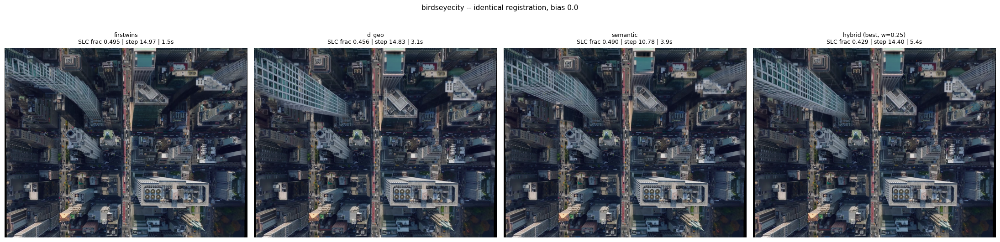

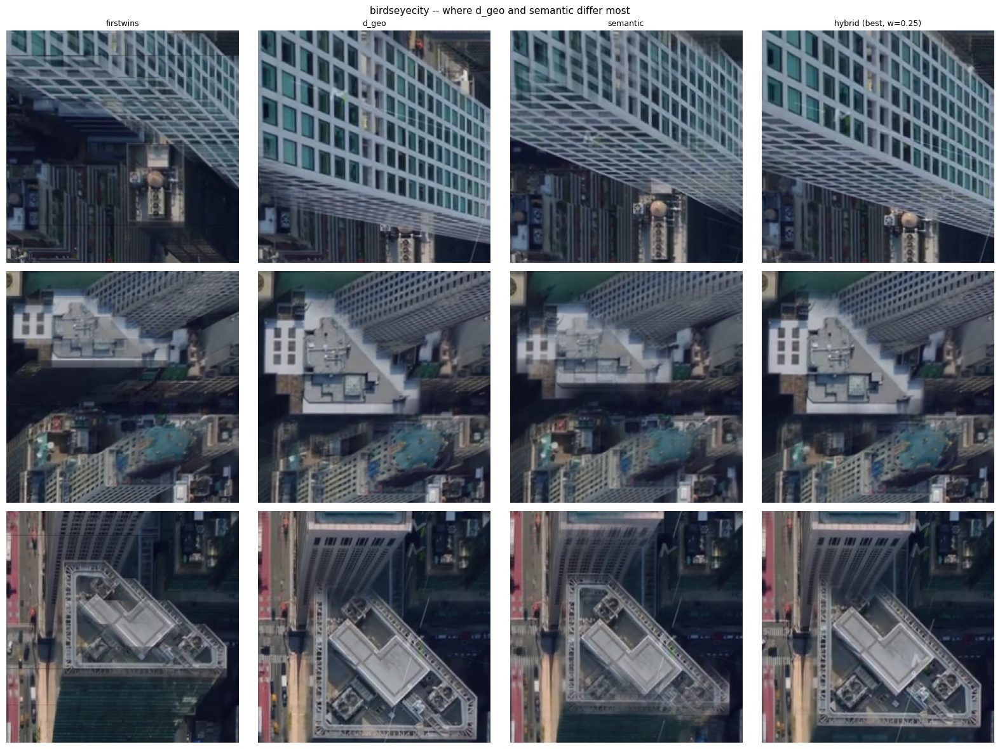

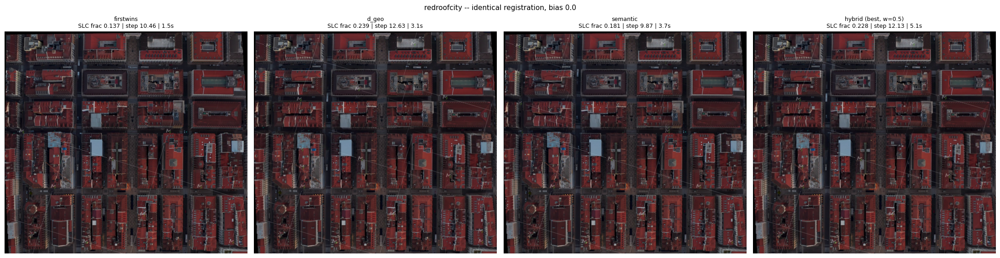

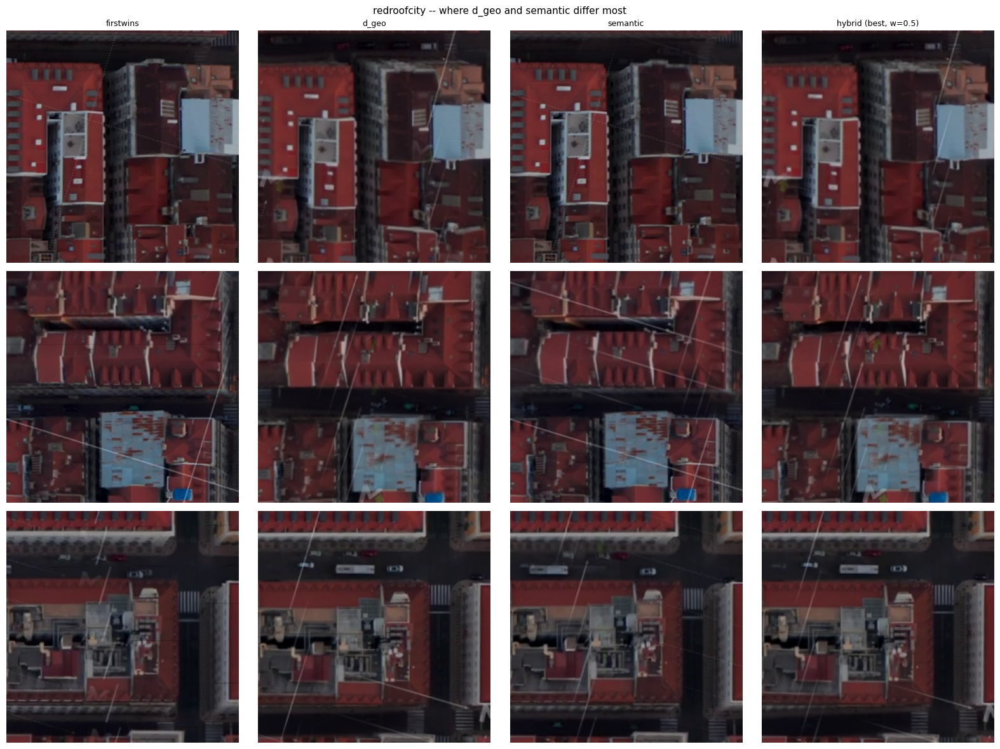

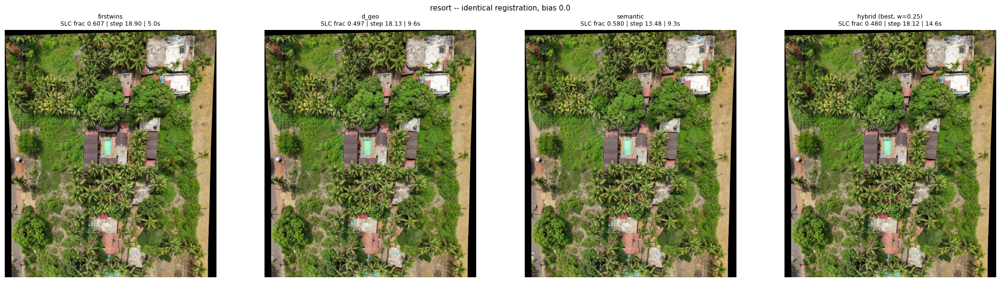

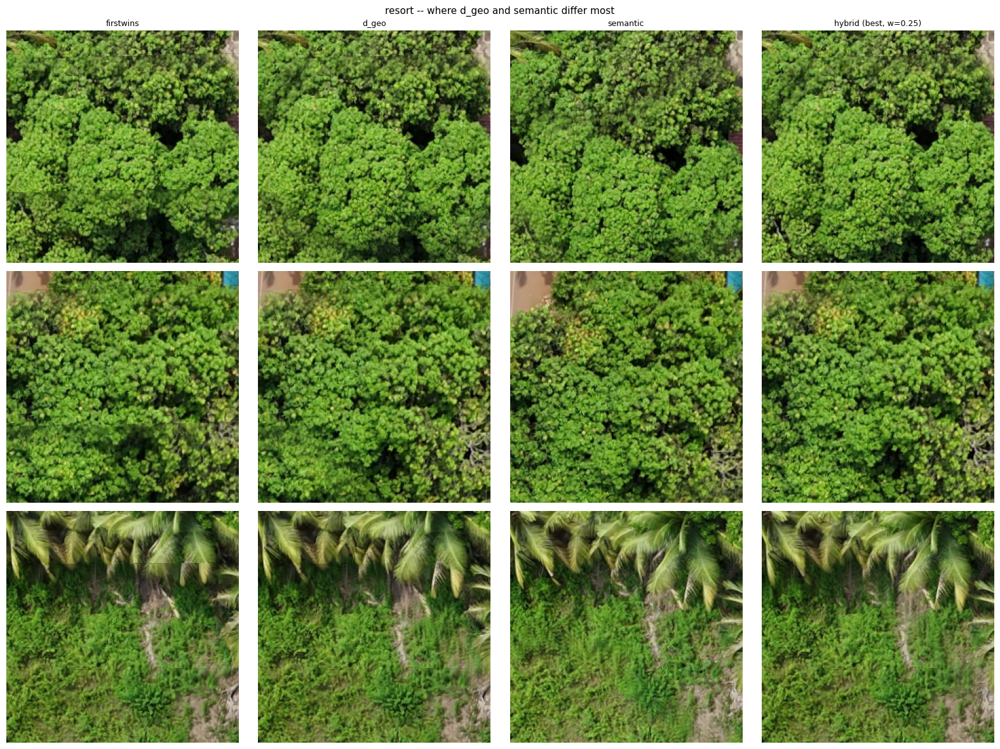

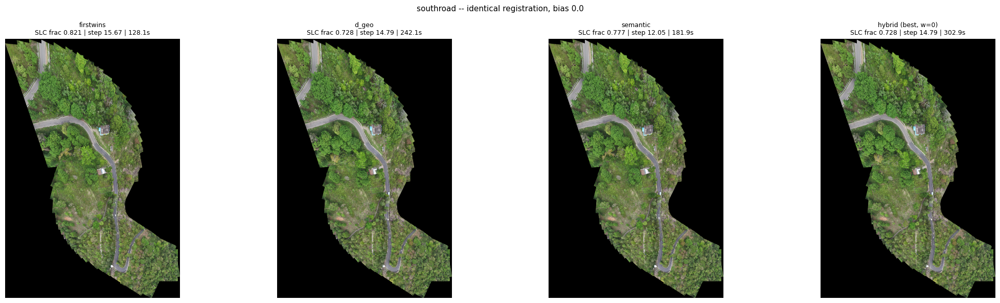

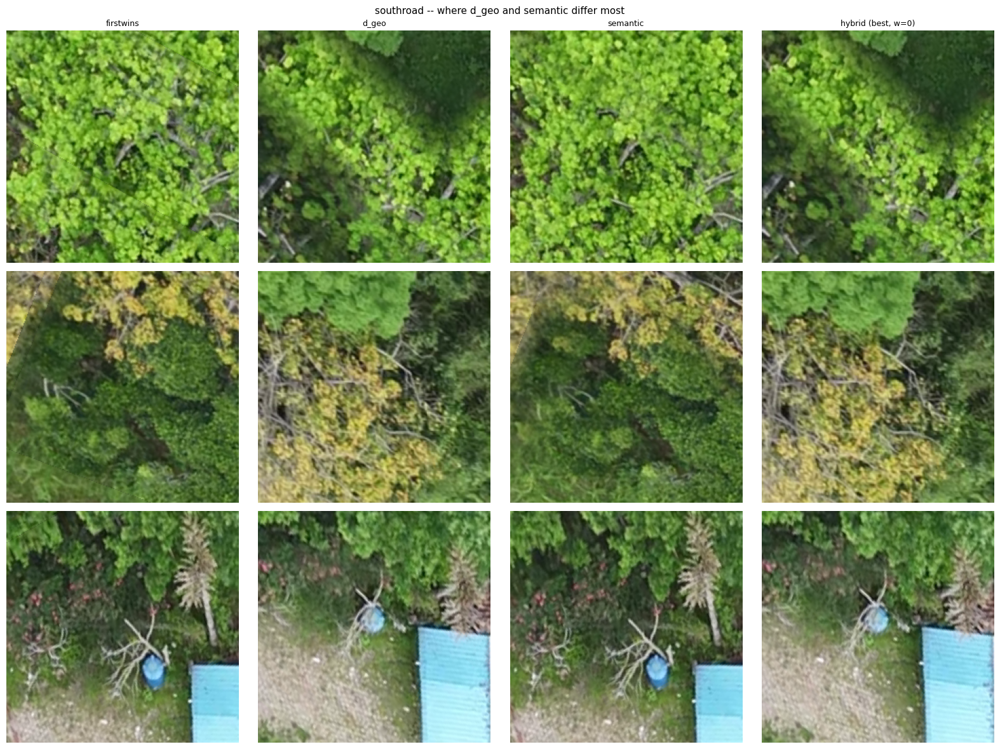

In [32]:
import matplotlib.pyplot as plt
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
tag = lambda k, w=None: vname(kind=k, bias=BIAS, w_sem=w)

for v in EVAL_VIDEOS:
    sub = EVAL_DF[EVAL_DF.video == v]
    hyb = sub[sub.kind == "hybrid"].sort_values("slc_frac_disagree").iloc[0]
    show = [("firstwins", "firstwins"), (tag("dgeo"), "d_geo"),
            (tag("semantic"), "semantic"), (hyb.variant, f"hybrid (best, w={hyb.w_sem:g})")]
    imgs = {n: cv2.imread(str(PASSB / v / n / "mosaic.png")) for n, _ in show}

    fig, ax = plt.subplots(1, 4, figsize=(22, 6))
    for a, (n, lab) in zip(ax, show):
        r = sub[sub.variant == n].iloc[0]
        a.imshow(cv2.cvtColor(imgs[n], cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{lab}\nSLC frac {r.slc_frac_disagree:.3f} | "
                    f"step {r.get('seam_step', np.nan):.2f} | {r.t_compose_s:.1f}s", fontsize=9)
    fig.suptitle(f"{v} -- identical registration, bias {BIAS}", fontsize=11)
    plt.tight_layout(); plt.savefig(FIG / f"{v}_mosaics.png", dpi=110); plt.show()

    a_, b_ = imgs[tag("dgeo")], imgs[tag("semantic")]
    diff = cv2.cvtColor(cv2.absdiff(a_, b_), cv2.COLOR_BGR2GRAY).astype(np.float32)
    tile = 256; H_, W_ = diff.shape
    cand = [(diff[y:y + tile, x:x + tile].mean(), y, x)
            for y in range(0, H_ - tile, tile // 2) for x in range(0, W_ - tile, tile // 2)]
    picks = []
    for s, y, x in sorted(cand, reverse=True):
        if all(abs(y - py) > tile or abs(x - px) > tile for _, py, px in picks):
            picks.append((s, y, x))
        if len(picks) == 3: break
    fig, ax = plt.subplots(len(picks), 4, figsize=(16, 4 * len(picks)), squeeze=False)
    for r_, (s, y, x) in enumerate(picks):
        for c_, (n, lab) in enumerate(show):
            ax[r_][c_].imshow(cv2.cvtColor(imgs[n][y:y + tile, x:x + tile], cv2.COLOR_BGR2RGB))
            ax[r_][c_].axis("off")
            if r_ == 0: ax[r_][c_].set_title(lab, fontsize=9)
    fig.suptitle(f"{v} -- where d_geo and semantic differ most", fontsize=11)
    plt.tight_layout(); plt.savefig(FIG / f"{v}_crops.png", dpi=110); plt.show()

In [33]:
# =============================================================================
# 15. Paired per-step significance test
# =============================================================================
# Reads the saved Pass B outputs only -- maps.npz per variant plus the Pass A
# frames. No recomposition, no GPU.
#
# Unit of pairing: the composition STEP. Every variant of a video shares the same
# composited frames at the same positions, so step k's seam exists in every
# variant and differs only by where the router put it. Seams between frames oa and
# ob are attributed to step max(oa, ob), the frame being added.
#
# The statistic tested is exactly the headline one -- seam-length-weighted
# fraction below SLC_THRESH -- so a bootstrap over steps tests the number in the
# table, not a proxy for it.
import numpy as np, pandas as pd, cv2, json

# ---- 0. make sure the NB_L2 state this cell needs is present ---------------
# Pass B does NOT need re-running after a kernel restart: EVAL_DF and BIAS are
# reloaded from disk. The functions still come from earlier cells.
_need = {"PASSA": "1 (config)", "PASSB": "1 (config)", "ROOT": "1 (config)",
         "EVAL_VIDEOS": "1 (config)", "HYBRID_W": "1 (config)",
         "SLC_WIN": "1 (config)", "SLC_THRESH": "1 (config)", "SLC_MAX_PTS": "1 (config)",
         "vname": "6 (composition, the Canvas/compose_variants cell)",
         "seam_pairs": "8 (SLC)", "adapt_trace": "7 (adapter)",
         "TRACES": "5 (Pass A driver -- fully cached, runs in seconds)"}
_missing = [f"{n}  <- rerun section {c}" for n, c in _need.items() if n not in globals()]
if _missing:
    raise NameError("rerun these NB_L2 cells first:\n  " + "\n  ".join(_missing))
if "BIAS" not in globals():
    BIAS = json.loads((ROOT / "frozen_bias.json").read_text())["bias"]
    print(f"BIAS reloaded from frozen_bias.json: {BIAS}")
if "EVAL_DF" not in globals():
    EVAL_DF = pd.read_csv(ROOT / "passB_results.csv")
    print(f"EVAL_DF reloaded from passB_results.csv: {len(EVAL_DF)} rows")

def slc_per_pair(owner, cov, place, win=SLC_WIN, max_pts=SLC_MAX_PTS, min_std=2.0,
                 seed=0, thresh=SLC_THRESH, min_valid=0.4):
    """Same arithmetic, sampling seed and pair order as slc_variant(), but keeps the
    per-pair counts instead of pooling them. Any divergence from slc_variant would
    show up in the reproduction check below."""
    rng = np.random.default_rng(seed)
    r = win // 2
    out = []
    for (oa, ob), (ys, xs) in seam_pairs(owner, cov).items():
        if len(ys) > max_pts:
            k = rng.choice(len(ys), max_pts, replace=False); ys, xs = ys[k], xs[k]
        y0, y1 = max(ys.min() - r - 1, 0), ys.max() + r + 2
        x0, x1 = max(xs.min() - r - 1, 0), xs.max() + r + 2
        size = (x1 - x0, y1 - y0)
        Tr = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]], float)
        ga, ma = place(oa, Tr, size); gb, mb = place(ob, Tr, size)
        ga = ga.astype(np.float32); gb = gb.astype(np.float32)
        m = (ma & mb).astype(np.float32)
        box = lambda z: cv2.boxFilter(z, cv2.CV_32F, (win, win), normalize=False,
                                      borderType=cv2.BORDER_CONSTANT)
        cnt = box(m); n_ = np.maximum(cnt, 1.0)
        mua, mub = box(ga * m) / n_, box(gb * m) / n_
        sa = np.sqrt(np.maximum(box(ga * ga * m) / n_ - mua ** 2, 0))
        sb = np.sqrt(np.maximum(box(gb * gb * m) / n_ - mub ** 2, 0))
        cab = box(ga * gb * m) / n_ - mua * mub
        yy, xx = ys - y0, xs - x0
        good = ((cnt[yy, xx] >= min_valid * win * win) &
                (sa[yy, xx] > min_std) & (sb[yy, xx] > min_std))
        v = (cab[yy, xx] / np.maximum(sa[yy, xx] * sb[yy, xx], 1e-6))[good]
        out.append(dict(oa=int(oa), ob=int(ob), step=int(max(oa, ob)),
                        n=int(len(v)), n_dis=int((v < thresh).sum())))
    return out


def step_table(video, name):
    """Per-step (n, n_dis) for one saved variant, re-derived from maps.npz."""
    d = PASSB / video / name
    if not (d / "maps.npz").exists():
        raise FileNotFoundError(f"{d / 'maps.npz'} -- was Pass B run with save=True?")
    z = np.load(d / "maps.npz")
    owner, cov, T = z["owner"], z["cov"].astype(bool), z["T"]
    tr = adapt_trace(video)
    Gs = {int(k): np.array(v) for k, v in tr["Gs"].items()}
    names, fdir, cache = tr["frames"], PASSA / video / "frames", {}

    def place(o, M, sz):
        if o not in cache:
            g = cv2.imread(str(fdir / names[o]), cv2.IMREAD_GRAYSCALE)
            if g is None:
                raise FileNotFoundError(fdir / names[o])
            cache[o] = g
        g = cache[o]; Mo = M @ T @ Gs[o]
        return (cv2.warpPerspective(g, Mo, sz, flags=cv2.INTER_LINEAR),
                cv2.warpPerspective(np.full(g.shape, 255, np.uint8), Mo, sz,
                                    flags=cv2.INTER_NEAREST) > 127)

    df = pd.DataFrame(slc_per_pair(owner, cov, place))
    if df.empty:
        return pd.DataFrame(columns=["n", "n_dis"])
    return df.groupby("step")[["n", "n_dis"]].sum()


# ---- 1. per-step tables, with the reproduction check ------------------------
SIG_VARIANTS = ([("firstwins", dict(kind="firstwins"))] +
                [(vname(kind="dgeo", bias=BIAS), dict(kind="dgeo", bias=BIAS)),
                 (vname(kind="semantic", bias=BIAS), dict(kind="semantic", bias=BIAS))] +
                [(vname(kind="hybrid", bias=BIAS, w_sem=w), dict(kind="hybrid", bias=BIAS, w_sem=w))
                 for w in HYBRID_W] +
                [(vname(kind="random", bias=BIAS), dict(kind="random", bias=BIAS))])

STEPS, repro = {}, []
for v in EVAL_VIDEOS:
    for name, _ in SIG_VARIANTS:
        t = step_table(v, name)
        STEPS[(v, name)] = t
        got = t.n_dis.sum() / max(t.n.sum(), 1)
        ref = EVAL_DF.loc[(EVAL_DF.video == v) & (EVAL_DF.variant == name),
                          "slc_frac_disagree"]
        ref = float(ref.iloc[0]) if len(ref) else np.nan
        repro.append(dict(video=v, variant=name, recomputed=got, table=ref,
                          abs_diff=abs(got - ref), n_steps=len(t)))
    print(f"  {v:13s} per-step tables built for {len(SIG_VARIANTS)} variants")

REPRO = pd.DataFrame(repro)
worst = REPRO.abs_diff.max()
print(f"\nreproduction check: max |recomputed - table| = {worst:.2e}")
if not worst < 1e-9:
    print(REPRO.sort_values("abs_diff", ascending=False).head(8).to_string(index=False))
    raise RuntimeError("per-step SLC does not reproduce the Pass B table -- stop, the "
                       "test would not be testing the reported numbers")
print("  PASS -- the per-step totals are exactly the Pass B numbers")

long = pd.concat([t.assign(video=v, variant=n).reset_index()
                  for (v, n), t in STEPS.items()], ignore_index=True)
long.to_csv(ROOT / "sig_per_step.csv", index=False)


# ---- 2. paired bootstrap over steps -----------------------------------------
N_BOOT = 10000

def paired_boot(a_name, b_name, videos, seed=0):
    """Resample shared (video, step) units with replacement; recompute the
    length-weighted fraction for both variants on the same resample.
    delta < 0 means A cuts through LESS disagreement than B."""
    A = pd.concat([STEPS[(v, a_name)].assign(video=v) for v in videos])
    B = pd.concat([STEPS[(v, b_name)].assign(video=v) for v in videos])
    A = A.reset_index().set_index(["video", "step"])
    B = B.reset_index().set_index(["video", "step"])
    idx = A.index.intersection(B.index)
    if len(idx) < 3:
        return dict(n_steps=len(idx), delta=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan)
    an, ad = A.loc[idx, "n"].to_numpy(float), A.loc[idx, "n_dis"].to_numpy(float)
    bn, bd = B.loc[idx, "n"].to_numpy(float), B.loc[idx, "n_dis"].to_numpy(float)
    obs = ad.sum() / max(an.sum(), 1) - bd.sum() / max(bn.sum(), 1)
    s = np.random.default_rng(seed).integers(0, len(idx), (N_BOOT, len(idx)))
    diffs = (ad[s].sum(1) / np.maximum(an[s].sum(1), 1)
             - bd[s].sum(1) / np.maximum(bn[s].sum(1), 1))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    p = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
    return dict(n_steps=len(idx), delta=obs, ci_lo=lo, ci_hi=hi, p=p)

D, S, R, F = (vname(kind="dgeo", bias=BIAS), vname(kind="semantic", bias=BIAS),
              vname(kind="random", bias=BIAS), "firstwins")
HY = [vname(kind="hybrid", bias=BIAS, w_sem=w) for w in HYBRID_W]
COMPARISONS = ([(vname(kind="hybrid", bias=BIAS, w_sem=0.25), D, "headline: does w=0.25 beat d_geo?")] +
               [(x, R, "vs random control") for x in [D, S, F] + HY] +
               [(x, F, "vs firstwins floor") for x in [D, S] + HY])

rows = []
for a, b, why in COMPARISONS:
    if a == b:
        continue
    for scope in EVAL_VIDEOS + ["ALL"]:
        vids = EVAL_VIDEOS if scope == "ALL" else [scope]
        rows.append(dict(scope=scope, A=a, B=b, question=why, **paired_boot(a, b, vids)))
SIG = pd.DataFrame(rows)

# Holm-Bonferroni across the pooled tests, since many comparisons are run at once.
pooled = SIG[SIG.scope == "ALL"].sort_values("p")
m = len(pooled)
holm = np.maximum.accumulate([(m - i) * p for i, p in enumerate(pooled.p)])
SIG.loc[pooled.index, "p_holm"] = np.minimum(holm, 1.0)

def verdict(r):
    # column is "delta", not "diff": r.diff would return pandas' Series.diff method
    if not np.isfinite(r["delta"]): return "too few steps"
    if r["ci_hi"] < 0: return "A better"
    if r["ci_lo"] > 0: return "B better"
    return "no detectable difference"
SIG["verdict"] = SIG.apply(verdict, axis=1)
SIG.to_csv(ROOT / "sig_paired_bootstrap.csv", index=False)

fmt = lambda x: f"{x:+.4f}" if isinstance(x, float) else x
show = ["A", "B", "n_steps", "delta", "ci_lo", "ci_hi", "p", "p_holm", "verdict"]
print(f"\n=== POOLED over all {len(EVAL_VIDEOS)} videos ({N_BOOT} resamples; delta < 0 = A better) ===")
print(SIG[SIG.scope == "ALL"][show].to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print("\n=== per video: the headline question ===")
hl = SIG[SIG.question.str.startswith("headline")]
print(hl[["scope"] + show[2:-2] + ["verdict"]].to_string(index=False,
                                                         float_format=lambda x: f"{x:+.4f}"))
print("\n=== per video: routed methods vs the random control ===")
vr = SIG[(SIG.question == "vs random control") & (SIG.scope != "ALL")]
print(vr.pivot_table(index="A", columns="scope", values="delta",
                     aggfunc="first").round(4).to_string())
print("\nsignificant (95% CI excludes 0) per video, vs random:")
print(vr.pivot_table(index="A", columns="scope", values="verdict",
                     aggfunc="first").to_string())
print("\nCaveat: steps along one chain are not fully independent -- a seam placed at")
print("step k shapes the canvas step k+1 sees -- so these intervals are somewhat")
print("optimistic. Read 'no detectable difference' as reliable and a narrow win as")
print("provisional.")

  birdseyecity  per-step tables built for 9 variants
  redroofcity   per-step tables built for 9 variants
  resort        per-step tables built for 9 variants
  southroad     per-step tables built for 9 variants

reproduction check: max |recomputed - table| = 0.00e+00
  PASS -- the per-step totals are exactly the Pass B numbers

=== POOLED over all 4 videos (10000 resamples; delta < 0 = A better) ===
           A         B  n_steps   delta   ci_lo   ci_hi       p  p_holm                  verdict
hyb_w0.25_b0   dgeo_b0       97 +0.0046 -0.0287 +0.0394 +0.7814 +1.0000 no detectable difference
     dgeo_b0 random_b0       95 -0.0328 -0.0763 +0.0131 +0.1578 +1.0000 no detectable difference
      sem_b0 random_b0       95 +0.0038 -0.0470 +0.0538 +0.8676 +1.0000 no detectable difference
   firstwins random_b0       93 +0.0426 -0.0066 +0.0912 +0.0870 +1.0000 no detectable difference
   hyb_w0_b0 random_b0       95 -0.0328 -0.0763 +0.0131 +0.1578 +1.0000 no detectable difference
hyb_w0.25_b0 r

## What this notebook establishes, and what it does not

**Establishes.** A seam-variant comparison on four evaluation videos with shared
registration, LeanGate frame selection, re-plan on rejection, and one bias chosen on
held-out MovingDrone data and frozen before evaluation — scored by a metric validated
against a known-parallax scene, with runtimes per variant and per stage.

**Does not establish.**
- **That SLC transfers to real footage unchanged.** The threshold (0.5) was fixed on
  synthetic data where aligned frames correlate at exactly 1.0. Real frames differ in
  exposure, noise and resampling, so aligned NCC sits below 1 — `firstwins` and
  `random_seam` rows are what show where the real distribution falls.
- **Independence from `d_geo`.** SLC measures the same physical quantity `d_geo` routes
  on, via pixels. A `d_geo` win is evidence DKM's flow was right, not a separate verdict.
- **Generalisation of the bias.** Selected on three rendered, oblique sequences and
  applied to real near-nadir footage. The per-family diagnostic shows its cost to each
  family; the domain gap is untested.

**Carried from Pass A.** The gate never binds on three of four evaluation videos — frame
count there is set by the gap ceiling of 64, not registrability. The re-plan retries
gap 64 from every new reference even right after it failed, costing ~14% of DKM calls on
southroad.

**Frozen constants the bias is relative to.** `AGE_BIAS = 0.5` is added on top of the
selected bias; `FEATHER_PX = 24`. Both inherited from NB_FINAL_EVALUATION.